# Trustworthy Diabetic Retinopathy Grading
## Ordinal Conformal Risk Control under Label Noise and Domain Shift

**Dataset:** Diabetic Retinopathy 2015 Data Colored Resized (EyePACS; source images are 224×224, 5 grades). **Model input:** 224×224, kept at the dataset's released resolution to match the original notebook and reduce GPU memory pressure.

| Phase | Research question | What runs |
|---|---|---|
| 0 | Audit | patient IDs, eye correlation, near-duplicates, uint8 cache, patient-level split |
| 1 | RQ1 leakage | image-level vs patient-level split, 3 seeds |
| 2 | RQ3 backbone x head | **4 backbones** (EffNet-B0, EffNet-B3, ConvNeXt-T, DINOv2-S; RETFound optional) x 3 heads (CE, regression, CORN), successive halving, then preprocessing ablation |
| 3 | RQ3 uncertainty | **4 methods**: temperature scaling, deep ensemble, MC-dropout, evidential, compared on ECE / NLL / Brier / AURC |
| 4 | RQ4 (main) | ordinal conformal risk control: bound FNR for referable DR (grade ≥ 2) |
| 5 | RQ2 label noise | 5-fold out-of-fold predictions, cleanlab, relabel / drop / soft-label retraining |
| 6 | RQ5 domain shift | APTOS 2019 (plus optional Messidor-2 / IDRiD), guarantee check, 200-image recalibration |
| 7 | Stretch | Grad-CAM, pointing game on IDRiD masks if available |

### How to run on Kaggle
1. Add the dataset as input. For Phase 6 also add `aptos2019-blindness-detection`. Turn **Internet on** the first time so `timm` can download pretrained weights, or upload the weights as a Kaggle dataset.
2. **Input stays at 224×224.** The cache is stored at the same source resolution, and the model receives 224×224 batches. No upscaling is performed.
3. The original `BS=64` and `PRED_BS=256` settings are restored. If you still hit GPU out-of-memory errors, lower `BS` to 32, 16, or 8 and lower `PRED_BS` separately; smaller batches use less GPU memory but can run slower.
4. Set `CFG["DEBUG"]=True` first to smoke-test the notebook. Debug results are not publishable final results.
5. The pipeline has a per-session time guard and may need multiple Kaggle sessions. Save the `/kaggle/working` outputs as a notebook version and attach them as an input dataset when continuing. The setup cell can restore matching `cache`, `ckpt`, `runs`, and `results` folders from an attached output root; set `CFG["RESUME_ROOT"]` if automatic detection does not find it.
6. At the end, the final evaluation cell produces an aggregate 5-fold out-of-fold confusion matrix (when Phase 5 is enabled) and a separate held-out-test confusion matrix for the selected model. The export cell writes a downloadable PyTorch bundle and inference package to the working directory.

**Novelty:** each ingredient exists separately. The contribution is the combined, leakage-free protocol. Run a literature search before claiming novelty.

## 0. Setup and configuration

In [1]:
import os, sys, time, json, math, glob, random, warnings, gc, subprocess, threading, queue, shutil
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
warnings.filterwarnings("ignore")

def _pip(*pk):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pk], check=False)
try: import timm
except ImportError: _pip("timm"); import timm
try: import cleanlab
except ImportError: _pip("cleanlab"); import cleanlab

import numpy as np, pandas as pd, cv2, torch, torch.nn as nn, torch.nn.functional as F
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display
from sklearn.metrics import cohen_kappa_score, roc_auc_score, roc_curve, confusion_matrix
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from scipy.optimize import minimize_scalar

CFG = dict(
    DEBUG=False,            # True = smoke test on ~1.6k images, 1 epoch
    DEBUG_PATIENTS=800,
    SEED=42,
    DATA_ROOT=None,         # auto-detected if None
    RESUME_ROOT=None,       # optional path to previous output root containing cache/ckpt/runs/results
    IMG_SIZE=224,           # keep the original 224x224 model input
    BS=64,                  # original training batch size at 224x224
    PRED_BS=256,            # original prediction/evaluation batch size
    SAMPLER_POWER=0.5,      # 0 = natural distribution, 1 = fully balanced
    HEAD_DROP=0.3,
    N_SEEDS=3,              # seeds for leakage study / key models
    EPOCHS_LEAK=8,
    EPOCHS_RUNG1=3,         # successive halving, rung 1
    RUNG2_KEEP=5,           # configs kept after rung 1
    EPOCHS_GRID=10,         # rung 2 / final recipe epochs
    EPOCHS_OOF=5,
    EPOCHS_NOISE=8,
    ENS_N=5,
    MC_T=20,
    SOFT_MIX=0.5,           # weight of OOF probabilities in soft labels
    ALPHAS=[0.02, 0.05, 0.10, 0.15, 0.20],
    ALPHA_MAIN=0.05,
    N_BOOT=300,
    RECAL_N=200,            # target images used for recalibration
    SESSION_LIMIT_H=11.5,   # stop cleanly before Kaggle's 12 h cap
    BUILD_CLAHE=True,
    RETFOUND_CKPT=None,     # e.g. "/kaggle/input/retfound/RETFound_cfp_weights.pth" (optional 5th backbone)
    IDRID_ROOT=None,        # optional external set paths, see Phase 6
    IDRID_MASK_DIR=None,    # optional lesion masks for the pointing game
    MESSIDOR2=None,         # dict(img_dir=..., csv=..., id_col=..., label_col=..., ext=".png")
)
RUN = dict(leak=True, grid=True, unc=True, conformal=True, noise=True, external=True, gradcam=True)

if CFG["DEBUG"]:
    CFG.update(EPOCHS_LEAK=1, EPOCHS_RUNG1=1, EPOCHS_GRID=1, EPOCHS_OOF=1, EPOCHS_NOISE=1, N_SEEDS=2, ENS_N=2,
               MC_T=5, N_BOOT=30, RUNG2_KEEP=2)

ON_KAGGLE = Path("/kaggle/working").exists()
WORK = Path("/kaggle/working") if ON_KAGGLE else Path("./work")
CACHE = WORK / ("cache_dbg" if CFG["DEBUG"] else "cache")
CK = WORK / "ckpt"
OUT = WORK / ("runs_dbg" if CFG["DEBUG"] else "runs")
RES = WORK / "results"
for p in (WORK, CACHE, CK, OUT, RES): p.mkdir(parents=True, exist_ok=True)

# Restore previous outputs when a saved Kaggle working directory is added as an input dataset.
# Set CFG["RESUME_ROOT"] manually if auto-detection cannot identify that dataset root.
resume_root = Path(CFG["RESUME_ROOT"]) if CFG["RESUME_ROOT"] else None
resume_names = [CACHE.name, CK.name, OUT.name, RES.name]
if ON_KAGGLE and resume_root is None:
    candidates = []
    input_root = Path("/kaggle/input")
    if input_root.exists():
        for parent in input_root.iterdir():
            if not parent.is_dir():
                continue
            roots_to_check = [parent] + [child for child in parent.iterdir() if child.is_dir()]
            for candidate in roots_to_check:
                score = sum((candidate / name).is_dir() for name in resume_names)
                if score >= 3:
                    candidates.append((score, candidate))
    if candidates:
        resume_root = sorted(candidates, key=lambda item: (item[0], str(item[1])))[-1][1]

if resume_root and resume_root.is_dir():
    restored = []
    for name, dest in zip(resume_names, (CACHE, CK, OUT, RES)):
        source_dir = resume_root / name
        dest_is_empty = not any(dest.iterdir())
        if source_dir.is_dir() and dest_is_empty:
            shutil.copytree(source_dir, dest, dirs_exist_ok=True)
            restored.append(name)
    if restored:
        print(f"Restored prior run from {resume_root}: {', '.join(restored)}")
    else:
        print(f"Resume root found at {resume_root}, but output folders were already populated or no matching folders existed.")
else:
    print("No prior run restore found. New cache/checkpoints will be created as needed.")

LEDGER = RES / "gpu_ledger.json"

DEV = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.benchmark = True
T0 = time.time()
K = 5
CLASSES = ["No_DR", "Mild", "Moderate", "Severe", "Proliferate_DR"]
print("device:", DEV, torch.cuda.get_device_name(0) if DEV == "cuda" else "", "| timm", timm.__version__)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def check_time():
    if time.time() - T0 > CFG["SESSION_LIMIT_H"] * 3600:
        raise RuntimeError("Session time budget reached. State is cached: save a version and re-run this cell in a new session.")

def ledger_add(phase, tag, secs):
    L = json.loads(LEDGER.read_text()) if LEDGER.exists() else []
    L.append(dict(phase=phase, tag=tag, sec=round(secs, 1)))
    LEDGER.write_text(json.dumps(L))

TABLES = {}
def save_table(name, d, show=True):
    TABLES[name] = d
    d.to_csv(RES / f"{name}.csv", index=False)
    if show: display(d)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 kB 15.0 MB/s eta 0:00:00
No prior run restore found. New cache/checkpoints will be created as needed.
device: cuda Tesla T4 | timm 1.0.29


## 1. Data audit
Parse patient ID and eye from the file name (`10_left` -> patient 10). Both eyes of one patient share a prefix, which is the source of the leakage that RQ1 measures.

In [2]:
def find_data_root():
    if CFG["DATA_ROOT"]: return CFG["DATA_ROOT"]
    for root, dirs, _ in os.walk("/kaggle/input"):
        if "No_DR" in dirs: return root
    raise FileNotFoundError("Could not find a folder containing No_DR. Set CFG['DATA_ROOT'].")

DATA_ROOT = find_data_root()
subdirs = {d.lower(): d for d in os.listdir(DATA_ROOT) if os.path.isdir(os.path.join(DATA_ROOT, d))}
prefixes = ["no", "mild", "moder", "sev", "prolif"]
class_dir = {}
for k, pre in enumerate(prefixes):
    class_dir[k] = next(v for lo, v in subdirs.items() if lo.startswith(pre))
rows = []
for k, d in class_dir.items():
    for e in os.scandir(os.path.join(DATA_ROOT, d)):
        if e.name.lower().endswith((".png", ".jpg", ".jpeg")):
            rows.append((e.path, Path(e.name).stem, k))
df = pd.DataFrame(rows, columns=["path", "image", "label"]).sort_values("image").reset_index(drop=True)
ex = df.image.str.extract(r"^(\d+)_(left|right)", expand=True)
df["patient"], df["eye"] = ex[0], ex[1]
PATIENT_OK = df.patient.notna().mean() > 0.95
if not PATIENT_OK:
    print("WARNING: patient prefix not found in file names. Recover pairs from trainLabels.csv, otherwise RQ1 is invalid.")
    df["patient"] = df.image
df["patient"] = df.patient.fillna(df.image)

if CFG["DEBUG"]:
    rng = np.random.default_rng(0)
    keep_p = rng.choice(df.patient.unique(), CFG["DEBUG_PATIENTS"], replace=False)
    df = df[df.patient.isin(keep_p)].reset_index(drop=True)

print(f"{len(df)} images | {df.patient.nunique()} patients | patient prefix parsed: {PATIENT_OK}")
cnt = df.label.value_counts().sort_index()
display(pd.DataFrame({"class": CLASSES, "n": cnt.values, "pct": (100 * cnt.values / len(df)).round(2)}))

35126 images | 17563 patients | patient prefix parsed: True


,class,n,pct
0,No_DR,25810,73.48
1,Mild,2443,6.95
2,Moderate,5292,15.07
3,Severe,873,2.49
4,Proliferate_DR,708,2.02


In [3]:
# Both eyes of a patient are strongly correlated: this is why image-level splits leak.
piv = df.pivot_table(index="patient", columns="eye", values="label", aggfunc="first").dropna()
if len(piv) > 10:
    k_eye = cohen_kappa_score(piv["left"].astype(int), piv["right"].astype(int), weights="quadratic")
    same = (piv["left"] == piv["right"]).mean()
    print(f"Patients with both eyes: {len(piv)} | left/right QWK = {k_eye:.3f} | identical grade in {100*same:.1f}% of pairs")
    print("Images per patient:", df.groupby("patient").size().value_counts().to_dict())

Patients with both eyes: 17563 | left/right QWK = 0.855 | identical grade in 87.2% of pairs
Images per patient: {2: 17563}


## 2. Cache source images as uint8 arrays, then dedupe
The released files are already 224×224. Cache them once at their source resolution, together with a 256-bit difference hash and 32×32 thumbnail. The model uses this same 224×224 resolution, avoiding unnecessary upscaling and extra activation memory.

In [4]:
RAW, HASH, THUMB = CACHE / "raw.npy", CACHE / "hash.npy", CACHE / "thumb.npy"
SRC_IMG = 224                         # resolution in this released dataset
IMG = int(CFG["IMG_SIZE"])            # model input resolution, kept at 224
if IMG < SRC_IMG:
    print(f"WARNING: model input ({IMG}) is smaller than source ({SRC_IMG}); details may be lost.")

def dhash_bits(img):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    g = cv2.resize(g, (17, 16), interpolation=cv2.INTER_AREA)
    return np.packbits((g[:, 1:] > g[:, :-1]).reshape(-1))      # 256 bits -> 32 bytes

def read_rgb(path, size=SRC_IMG):
    im = cv2.imread(path, cv2.IMREAD_COLOR)
    if im is None: raise ValueError(f"Could not decode image: {path}")
    im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    if im.shape[:2] != (size, size): im = cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA)
    return im

if not RAW.exists():
    N = len(df); tmp = CACHE / "raw_tmp.npy"
    mm = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.uint8, shape=(N, SRC_IMG, SRC_IMG, 3))
    H = np.zeros((N, 32), np.uint8); TH = np.zeros((N, 32 * 32 * 3), np.uint8)
    paths = df.path.values
    def work(i):
        im = read_rgb(paths[i]); mm[i] = im; H[i] = dhash_bits(im)
        TH[i] = cv2.resize(im, (32, 32), interpolation=cv2.INTER_AREA).reshape(-1)
    with ThreadPoolExecutor(4) as ex_:
        list(tqdm(ex_.map(work, range(N)), total=N, desc="caching source images"))
    mm.flush(); del mm
    np.save(HASH, H); np.save(THUMB, TH); os.replace(tmp, RAW)
print("source-resolution raw cache:", RAW, f"{RAW.stat().st_size/1e9:.2f} GB")
print(f"source={SRC_IMG}x{SRC_IMG}; model input={IMG}x{IMG}.")

caching source images:   0%|          | 0/35126 [00:00<?, ?it/s]

source-resolution raw cache: /kaggle/working/cache/raw.npy 5.29 GB
source=224x224; model input=224x224.


In [5]:
# Near-duplicate removal: 256-bit hash, Hamming <= 6, pigeonhole over 8 x 32-bit chunks, verified on thumbnails.
H, TH = np.load(HASH), np.load(THUMB).astype(np.int16)

def near_dup_roots(H, TH, max_ham=6, bucket_cap=150, mad_thr=8.0):
    N = len(H); parent = np.arange(N)
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]; a = parent[a]
        return a
    pop = np.array([bin(i).count("1") for i in range(256)], np.uint8)
    for c in range(8):
        keys = np.ascontiguousarray(H[:, 4 * c:4 * c + 4]).view(np.uint32).ravel()
        order = np.argsort(keys, kind="stable"); ks = keys[order]
        for grp in np.split(order, np.flatnonzero(np.diff(ks)) + 1):
            if len(grp) < 2 or len(grp) > bucket_cap: continue
            sub = H[grp]
            for a in range(len(grp) - 1):
                d = pop[np.bitwise_xor(sub[a], sub[a + 1:])].sum(1)
                for b in np.flatnonzero(d <= max_ham):
                    i, j = grp[a], grp[a + 1 + b]
                    if np.abs(TH[i] - TH[j]).mean() < mad_thr:
                        ri, rj = find(i), find(j)
                        if ri != rj: parent[max(ri, rj)] = min(ri, rj)
    return np.array([find(i) for i in range(N)])

roots = near_dup_roots(H, TH)
df["dup_root"] = roots
df["keep"] = ~pd.Series(roots).duplicated().values
grp_lab = df.groupby("dup_root").label.nunique()
print(f"Near-duplicates dropped: {(~df.keep).sum()} | duplicate clusters with conflicting labels: {(grp_lab > 1).sum()} "
      f"(direct evidence of label noise)")
df.drop(columns=["path"]).to_csv(RES / "meta.csv", index=False)

Near-duplicates dropped: 2252 | duplicate clusters with conflicting labels: 167 (direct evidence of label noise)


In [6]:
def clahe_img(img):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

CLAHE_P = CACHE / "clahe.npy"
def ensure_clahe():
    if CLAHE_P.exists(): return
    raw = np.load(RAW, mmap_mode="r"); tmp = CACHE / "clahe_tmp.npy"
    out = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.uint8, shape=raw.shape)
    def w(i): out[i] = clahe_img(np.ascontiguousarray(raw[i]))
    with ThreadPoolExecutor(4) as ex_: list(tqdm(ex_.map(w, range(len(raw))), total=len(raw), desc="clahe"))
    out.flush(); del out; os.replace(tmp, CLAHE_P)
if CFG["BUILD_CLAHE"]: ensure_clahe()

clahe:   0%|          | 0/35126 [00:00<?, ?it/s]

## 3. Splits (patient-level and image-level)
Patient-level: 70 / 10 / 20 stratified by each patient's worst grade, seeded. The image-level split has the same sizes but ignores patients. It is used only for the leakage study (RQ1).

In [7]:
def _split(ids, strat, test_size, seed):
    try: return train_test_split(ids, test_size=test_size, stratify=strat, random_state=seed)
    except ValueError: return train_test_split(ids, test_size=test_size, random_state=seed)

kdf = df[df.keep]
pt = kdf.groupby("patient").label.max()
p_trv, p_te = _split(pt.index.values, pt.values, 0.20, CFG["SEED"])
p_tr, p_va = _split(p_trv, pt.loc[p_trv].values, 0.125, CFG["SEED"])
SP = {n: df.index[df.keep & df.patient.isin(s)].values for n, s in [("train", p_tr), ("val", p_va), ("test", p_te)]}

ki = kdf.index.values
i_trv, i_te = _split(ki, kdf.label.values, 0.20, CFG["SEED"])
i_tr, i_va = _split(i_trv, df.label.values[i_trv], 0.125, CFG["SEED"])
SI = {"train": np.sort(i_tr), "val": np.sort(i_va), "test": np.sort(i_te)}

y = df.label.values.astype(np.int64); pat = df.patient.values
assert not set(pat[SP["train"]]) & set(pat[SP["test"]]) and not set(pat[SP["val"]]) & set(pat[SP["test"]])
tab = pd.DataFrame({f"{a}_{b}": np.bincount(y[S[b]], minlength=5) for a, S in [("patient", SP), ("image", SI)] for b in ("train", "val", "test")},
                   index=CLASSES)
display(tab)
leak_frac = np.isin(pat[SI["test"]], pat[SI["train"]]).mean()
print(f"Image-level split: {100*leak_frac:.1f}% of test images belong to a patient that also appears in train. Patient-level split: 0%.")

,patient_train,patient_val,patient_test,image_train,image_val,image_test
No_DR,16892,2442,4824,16910,2416,4832
Mild,1629,218,454,1611,230,460
Moderate,3459,487,982,3449,493,986
Severe,560,87,163,567,81,162
Proliferate_DR,474,69,134,474,68,135


Image-level split: 67.3% of test images belong to a patient that also appears in train. Patient-level split: 0%.


## 4. Core library: GPU data loader, models, losses, training loop
Augmentation runs on the GPU (random rotation, flip, scale, brightness and contrast). Rotation is a valid augmentation because fundus images have no canonical orientation.

In [8]:
_Xc = {}
def get_X(preproc):
    key = "clahe" if preproc == "clahe" else "raw"
    if key not in _Xc:
        if key == "clahe": ensure_clahe()
        _Xc[key] = np.load(CLAHE_P if key == "clahe" else RAW, mmap_mode="r")
    return _Xc[key]

class Loader:
    def __init__(self, X, y_, idx, bs, train=False, p=None, prefetch=4):
        self.X, self.y, self.idx, self.bs, self.train, self.p, self.pf = X, y_, np.asarray(idx), bs, train, p, prefetch
    def __len__(self): return math.ceil(len(self.idx) / self.bs)
    def __iter__(self):
        idx = self.idx
        if self.train:
            idx = np.random.choice(idx, size=len(idx), replace=True, p=self.p) if self.p is not None else np.random.permutation(idx)
        q = queue.Queue(self.pf)
        def prod():
            try:
                for i in range(0, len(idx), self.bs):
                    b = idx[i:i + self.bs]
                    if self.train and len(b) < 2: continue
                    xb = torch.from_numpy(self.X[b]); yb = torch.from_numpy(self.y[b])
                    if DEV == "cuda": xb = xb.pin_memory()
                    q.put((xb, yb, b))
            finally:
                q.put(None)
        threading.Thread(target=prod, daemon=True).start()
        while True:
            it = q.get()
            if it is None: break
            xb, yb, b = it
            yield xb.to(DEV, non_blocking=True), yb.to(DEV, non_blocking=True), b

MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)

def gpu_aug(x):
    B, d = x.size(0), x.device
    ang = (torch.rand(B, device=d) * 2 - 1) * math.pi
    sc = 1 + (torch.rand(B, device=d) * 2 - 1) * 0.10
    flip = (torch.rand(B, device=d) < 0.5).float() * 2 - 1
    c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
    z = torch.zeros_like(c)
    theta = torch.stack([torch.stack([c * flip, -s, z], 1), torch.stack([s * flip, c, z], 1)], 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, padding_mode="zeros", align_corners=False)
    br = 1 + (torch.rand(B, 1, 1, 1, device=d) * 2 - 1) * 0.2
    ct = 1 + (torch.rand(B, 1, 1, 1, device=d) * 2 - 1) * 0.2
    return (((x - 0.5) * ct + 0.5) * br).clamp(0, 1)

def prep(xb, train, preproc):
    # Source arrays and model inputs both stay at 224x224 in this configuration.
    x = xb.permute(0, 3, 1, 2).float() / 255.
    if x.shape[-2:] != (IMG, IMG):
        x = F.interpolate(x, size=(IMG, IMG), mode="bilinear", align_corners=False, antialias=True)
    if train: x = gpu_aug(x)
    if preproc == "ben":      # Ben Graham: 4*(img - gaussian_blur(img)) + 0.5
        scale = IMG / SRC_IMG
        kernel = max(3, int(round(25 * scale)))
        if kernel % 2 == 0: kernel += 1
        sigma = 3.7 * scale
        blur = TF.gaussian_blur(x, kernel_size=[kernel, kernel], sigma=[sigma, sigma])
        x = (4 * (x - blur) + 0.5).clamp(0, 1)
    x = (x - MEAN) / STD
    return x.contiguous(memory_format=torch.channels_last)

In [9]:
# Backbones and heads
BB = {
    "effb0":      dict(timm="efficientnet_b0", lr=6e-4, kw=dict(drop_path_rate=0.1)),
    "effb3":      dict(timm="efficientnet_b3", lr=4e-4, kw=dict(drop_path_rate=0.1)),
    "convnext_t": dict(timm="convnext_tiny", lr=1.5e-4, kw=dict(drop_path_rate=0.1)),
    "dinov2_s":   dict(timm="vit_small_patch14_dinov2.lvd142m", lr=6e-5, kw=dict(img_size=IMG, drop_path_rate=0.1)),
}
if CFG["RETFOUND_CKPT"] and Path(CFG["RETFOUND_CKPT"]).exists() and IMG == 224:
    BB["retfound"] = dict(timm="vit_large_patch16_224", lr=3e-5, kw=dict(global_pool="avg"), ckpt=CFG["RETFOUND_CKPT"], freeze_until=20)
    print("RETFound enabled: blocks 0-19 frozen, last 4 blocks + head fine-tuned")
HEAD_OUT = {"ce": 5, "reg": 1, "corn": 4, "evid": 5}

class Net(nn.Module):
    def __init__(self, enc, head, drop):
        super().__init__()
        self.enc, self.drop = enc, nn.Dropout(drop)
        self.fc = nn.Linear(enc.num_features, HEAD_OUT[head])
    def forward(self, x): return self.fc(self.drop(self.enc(x)))

def build_model(bb, head, pretrained=True):
    spec = BB[bb]
    use_pre = pretrained and "ckpt" not in spec
    try:
        enc = timm.create_model(spec["timm"], pretrained=use_pre, num_classes=0, **spec["kw"])
    except Exception as e:
        raise RuntimeError(f"Could not load pretrained weights for {bb} ({e}). Turn Internet on or attach the weights as a dataset. "
                           "Training from random init would silently invalidate the comparison.")
    if "ckpt" in spec and pretrained:
        sd = torch.load(spec["ckpt"], map_location="cpu"); sd = sd.get("model", sd)
        sd = {k: v for k, v in sd.items() if not k.startswith("head")}
        print("RETFound load:", enc.load_state_dict(sd, strict=False))
        import re
        for n, p in enc.named_parameters():
            m = re.search(r"blocks\.(\d+)\.", n)
            if m and int(m.group(1)) < spec["freeze_until"]: p.requires_grad = False
            if n.startswith(("patch_embed", "cls_token", "pos_embed")): p.requires_grad = False
    return Net(enc, head, CFG["HEAD_DROP"])

# Losses
def corn_loss(logits, y_, k=K):
    tot, n = 0., 0
    for j in range(k - 1):
        m = y_ >= j
        if m.sum() == 0: continue
        tot = tot + F.binary_cross_entropy_with_logits(logits[m, j], (y_[m] > j).float(), reduction="sum"); n += int(m.sum())
    return tot / max(n, 1)

def kl_dirichlet(alpha):
    beta = torch.ones_like(alpha)
    sa, sb = alpha.sum(1, keepdim=True), beta.sum(1, keepdim=True)
    return (torch.lgamma(sa) - torch.lgamma(alpha).sum(1, keepdim=True) + torch.lgamma(beta).sum(1, keepdim=True) - torch.lgamma(sb)
            + ((alpha - beta) * (torch.digamma(alpha) - torch.digamma(sa))).sum(1, keepdim=True))

def edl_loss(out, y_, frac):
    alpha = F.softplus(out) + 1; S = alpha.sum(1, keepdim=True)
    Y = F.one_hot(y_, K).float()
    A = (Y * (torch.digamma(S) - torch.digamma(alpha))).sum(1)
    lam = 0.1 * min(1.0, 2 * frac)
    return (A + lam * kl_dirichlet(Y + (1 - Y) * alpha).squeeze(1)).mean()

def compute_loss(out, y_, head, soft_b=None, frac=0.):
    out = out.float()
    if head == "ce":
        return -(soft_b * F.log_softmax(out, 1)).sum(1).mean() if soft_b is not None else F.cross_entropy(out, y_)
    if head == "reg":  return F.smooth_l1_loss(out.squeeze(1), y_.float())
    if head == "corn": return corn_loss(out, y_)
    if head == "evid": return edl_loss(out, y_, frac)

# Outputs -> class probabilities (numpy)
def softmax_np(z):
    z = z - z.max(-1, keepdims=True); e = np.exp(z); return e / e.sum(-1, keepdims=True)

def to_probs(out, head, sigma=0.6):
    out = np.asarray(out, np.float64)
    if head == "ce": return softmax_np(out)
    if head == "evid":
        a = np.logaddexp(0, out) + 1; return a / a.sum(-1, keepdims=True)
    if head == "reg":      # discretised Gaussian around the regression output; sigma fit on val NLL
        r = out[..., :1]; return softmax_np(-(r - np.arange(K)) ** 2 / (2 * sigma ** 2))
    if head == "corn":     # P(y>k) = prod_{j<=k} sigmoid(logit_j)
        S = np.cumprod(1 / (1 + np.exp(-out)), -1)
        P = np.zeros(out.shape[:-1] + (K,))
        P[..., 0] = 1 - S[..., 0]; P[..., 1:K - 1] = S[..., :-1] - S[..., 1:]; P[..., K - 1] = S[..., -1]
        P = np.clip(P, 1e-9, None); return P / P.sum(-1, keepdims=True)

def decode(out, head):
    if head == "reg": return np.clip(np.rint(out.reshape(-1)), 0, 4).astype(int)
    return np.clip(np.rint(to_probs(out, head) @ np.arange(K)), 0, 4).astype(int)

In [10]:
@torch.no_grad()
def predict(model, X, idx, y_all, preproc, bs=None):
    bs = int(bs or CFG["PRED_BS"])
    model.eval(); outs = []
    for xb, yb, b in Loader(X, y_all, idx, bs, False):
        with torch.autocast(device_type=DEV, dtype=torch.float16, enabled=DEV == "cuda"):
            o = model(prep(xb, False, preproc))
        outs.append(o.float().cpu().numpy())
    return np.concatenate(outs)

@torch.no_grad()
def predict_mc(model, X, idx, y_all, preproc, T=20, bs=None):
    """MC-dropout. Dropout lives only in the head, so encode once and resample the head T times (exact and fast)."""
    bs = int(bs or CFG["PRED_BS"])
    model.eval(); feats = []
    for xb, yb, b in Loader(X, y_all, idx, bs, False):
        with torch.autocast(device_type=DEV, dtype=torch.float16, enabled=DEV == "cuda"):
            feats.append(model.enc(prep(xb, False, preproc)).float())
    f = torch.cat(feats)
    return np.stack([model.fc(F.dropout(f, p=model.drop.p, training=True)).float().cpu().numpy() for _ in range(T)])

def fit_sigma(out_val, y_val):
    def nll(ls):
        P = to_probs(out_val, "reg", np.exp(ls)); return -np.log(P[np.arange(len(y_val)), y_val] + 1e-12).mean()
    return float(np.exp(minimize_scalar(nll, bounds=(-3, 1.5), method="bounded").x))

def qwk(a, b): return cohen_kappa_score(a, b, weights="quadratic")

def fit_cuts(r, y_, iters=3):
    cuts = np.array([0.5, 1.5, 2.5, 3.5])
    for _ in range(iters):
        for i in range(4):
            best, bv = cuts[i], qwk(y_, np.digitize(r, cuts))
            for v in np.linspace(cuts[i] - 0.5, cuts[i] + 0.5, 21):
                c = cuts.copy(); c[i] = v
                if np.all(np.diff(c) > 0):
                    s = qwk(y_, np.digitize(r, c))
                    if s > bv: best, bv = v, s
            cuts[i] = best
    return cuts

def load_run(tag):
    z = np.load(OUT / f"{tag}.npz", allow_pickle=True); return {k: z[k] for k in z.files}

def load_model(tag):
    r = load_run(tag); m = build_model(str(r["bb"]), str(r["head"]), pretrained=False)
    m.load_state_dict(torch.load(CK / f"{tag}_best.pt", map_location=DEV))
    return m.to(DEV).to(memory_format=torch.channels_last).eval()

def train_model(tag, bb, head, idx_tr, eval_sets, epochs, seed=0, preproc="raw", y_train=None, soft=None, lr=None, bs=None, phase=""):
    """Trains with AMP + channels_last + balanced sampler, checkpoints every epoch, keeps the best epoch by val QWK."""
    if (OUT / f"{tag}.npz").exists(): return load_run(tag)
    seed_all(seed); t0 = time.time(); bs = int(bs or min(CFG["BS"], CFG.get("BATCH_BY_BACKBONE", {}).get(bb, CFG["BS"])))
    X = get_X(preproc); y_all = y
    ytr = (y_train if y_train is not None else y_all).astype(np.int64)
    model = build_model(bb, head).to(DEV).to(memory_format=torch.channels_last)
    base = lr or BB[bb]["lr"]
    enc_p = [p for p in model.enc.parameters() if p.requires_grad]
    opt = torch.optim.AdamW([{"params": enc_p, "lr": base}, {"params": model.fc.parameters(), "lr": base * 5}], weight_decay=0.02)
    cnt = np.bincount(ytr[idx_tr], minlength=K).astype(float)
    w = (1.0 / np.maximum(cnt, 1)) ** CFG["SAMPLER_POWER"]; p = w[ytr[idx_tr]]; p /= p.sum()
    loader = Loader(X, ytr, idx_tr, bs, train=True, p=p)
    steps = len(loader) * epochs; warm = max(1, int(0.03 * steps))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: s / warm if s < warm else max(0.01, 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm)))))
    scaler = torch.cuda.amp.GradScaler(enabled=DEV == "cuda")
    rp, bp = CK / f"{tag}_resume.pt", CK / f"{tag}_best.pt"
    start, best, hist = 0, -9, []
    if rp.exists():
        c = torch.load(rp, map_location=DEV)
        model.load_state_dict(c["m"]); opt.load_state_dict(c["o"]); sched.load_state_dict(c["s"]); scaler.load_state_dict(c["sc"])
        start, best, hist = c["ep"] + 1, c["best"], c["hist"]; print(f"[{tag}] resumed at epoch {start}")
    yv = y_all[eval_sets["val"]]
    for ep in range(start, epochs):
        model.train(); tl, n = 0., 0
        for xb, yb, b in loader:
            x = prep(xb, True, preproc)
            sb = torch.from_numpy(soft[b]).to(DEV).float() if soft is not None else None
            with torch.autocast(device_type=DEV, dtype=torch.float16, enabled=DEV == "cuda"):
                out = model(x)
            loss = compute_loss(out, yb, head, sb, ep / epochs)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 2.0); scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(b); n += len(b)
        ov = predict(model, X, eval_sets["val"], y_all, preproc)
        q = qwk(yv, decode(ov, head)); hist.append(dict(ep=ep, loss=tl / n, val_qwk=q))
        print(f"[{tag}] ep {ep+1}/{epochs} loss {tl/n:.4f} val QWK {q:.4f} ({time.time()-t0:.0f}s)")
        if q > best: best = q; torch.save(model.state_dict(), bp)
        torch.save(dict(m=model.state_dict(), o=opt.state_dict(), s=sched.state_dict(), sc=scaler.state_dict(), ep=ep, best=best, hist=hist), rp)
        check_time()
    model.load_state_dict(torch.load(bp, map_location=DEV))
    res = dict(bb=bb, head=head, preproc=preproc, hist=json.dumps(hist), sigma=0.6, cuts=np.array([0.5, 1.5, 2.5, 3.5]))
    for name, idx in eval_sets.items():
        res[f"out_{name}"] = predict(model, X, idx, y_all, preproc); res[f"idx_{name}"] = np.asarray(idx)
    if head == "reg":
        res["sigma"] = fit_sigma(res["out_val"], yv); res["cuts"] = fit_cuts(res["out_val"].reshape(-1), yv)
    np.savez(OUT / f"{tag}.npz", **res)
    if rp.exists(): rp.unlink()
    ledger_add(phase, tag, time.time() - t0)
    del model, opt; gc.collect(); torch.cuda.empty_cache()
    return load_run(tag)

## 5. Metrics, calibration, selective prediction, cluster bootstrap

In [11]:
def entropy(P): return -(P * np.log(P + 1e-12)).sum(1)

def ece_score(P, y_, bins=15):
    conf, pred = P.max(1), P.argmax(1); acc = (pred == y_).astype(float); e = 0.
    edges = np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return e

def nll_score(P, y_): return float(-np.log(np.clip(P[np.arange(len(y_)), y_], 1e-12, 1)).mean())
def brier_score(P, y_): return float(((P - np.eye(K)[y_]) ** 2).sum(1).mean())

def sens_at_spec(ref, score, spec):
    fpr, tpr, _ = roc_curve(ref, score); ok = fpr <= 1 - spec
    return float(tpr[ok].max()) if ok.any() else 0.

def risk_coverage(unc, loss):
    o = np.argsort(unc, kind="stable"); l = loss[o]
    return np.arange(1, len(l) + 1) / len(l), np.cumsum(l) / np.arange(1, len(l) + 1)

def aurc(unc, loss): return float(risk_coverage(unc, loss)[1].mean())

def qwk_at_cov(y_, pred, unc, cov=0.8):
    keep = np.argsort(unc, kind="stable")[: int(cov * len(y_))]; return qwk(y_[keep], pred[keep])

def metric_row(P, pred, y_, unc=None):
    unc = entropy(P) if unc is None else unc
    ref, pr = (y_ >= 2).astype(int), P[:, 2:].sum(1)
    return dict(QWK=qwk(y_, pred), AUROC_ref=roc_auc_score(ref, pr), Sens_90spec=sens_at_spec(ref, pr, .90),
                Sens_95spec=sens_at_spec(ref, pr, .95), ECE=ece_score(P, y_), NLL=nll_score(P, y_), Brier=brier_score(P, y_),
                AURC=aurc(unc, (y_ - pred) ** 2 / 16.), QWK_80cov=qwk_at_cov(y_, pred, unc, .8))

def cluster_boot(fn, groups, n=300, seed=0):
    """Patient-level cluster bootstrap. fn(idx)->float. Returns (point, lo, hi, boots)."""
    rng = np.random.default_rng(seed); ug, inv = np.unique(groups, return_inverse=True)
    order = np.argsort(inv, kind="stable"); counts = np.bincount(inv); starts = np.r_[0, np.cumsum(counts)[:-1]]
    boots = []
    for _ in range(n):
        g = rng.integers(0, len(ug), len(ug))
        idx = np.concatenate([order[starts[i]:starts[i] + counts[i]] for i in g])
        try: boots.append(fn(idx))
        except Exception: pass
    boots = np.array(boots); pt_ = fn(np.arange(len(groups)))
    return pt_, np.percentile(boots, 2.5), np.percentile(boots, 97.5), boots

def ci_str(fn, groups, n=None):
    p, lo, hi, _ = cluster_boot(fn, groups, n or CFG["N_BOOT"]); return f"{p:.3f} [{lo:.3f}, {hi:.3f}]"

def get_eval(res, split):
    head = str(res["head"]); out = res["out_" + split]; idx = res["idx_" + split]
    P = to_probs(out, head, float(res["sigma"]))
    pred = np.digitize(out.reshape(-1), res["cuts"]) if head == "reg" else decode(out, head)
    return dict(P=P, pred=pred, y=y[idx], idx=idx, g=pat[idx])

def per_class_recall(y_, pred):
    cm = confusion_matrix(y_, pred, labels=range(K)); return np.diag(cm) / np.maximum(cm.sum(1), 1)

## 6. Conformal risk control for ordinal labels
For each image build a **contiguous ordinal prediction set**. Start at the modal grade and grow the set towards the more probable neighbour until its probability mass reaches `q`. Sets are nested in `q`.

*Loss:* an image with true grade >= 2 whose set contains no grade >= 2 (a missed referable case). It is monotone non-increasing in `q`.
*Calibration:* use calibration images with true grade >= 2 only, so the controlled risk is the **conditional FNR for referable DR**. Pick the smallest `q` with `(n*R_hat(q)+1)/(n+1) <= alpha`.
*Referral rule:* refer if the set contains any grade >= 2.

Because sets are nested, each image has a single score `s_i`, the mass just before the set first reaches grade 2. The image is missed iff `q <= s_i`. This makes calibration exact and fast.

In [12]:
def ordinal_sets(P, q):
    N = len(P); ar = np.arange(N); lo = P.argmax(1); hi = lo.copy(); mass = P[ar, lo].copy()
    for _ in range(K - 1):
        need = mass < q
        if not need.any(): break
        left = np.where(lo > 0, P[ar, np.maximum(lo - 1, 0)], -1.0)
        right = np.where(hi < K - 1, P[ar, np.minimum(hi + 1, K - 1)], -1.0)
        gl = need & (left >= right) & (lo > 0); gr = need & ~(left >= right) & (hi < K - 1)
        mass = mass + np.where(gl, left, 0) + np.where(gr, right, 0)
        lo = lo - gl; hi = hi + gr
    g = np.arange(K)[None]
    return (g >= lo[:, None]) & (g <= hi[:, None])

def crc_scores(P):
    """s_i = mass of the set just before it first contains a grade >= 2 (-1 if the mode is already >= 2)."""
    N = len(P); ar = np.arange(N); lo = P.argmax(1); hi = lo.copy(); mass = P[ar, lo].copy()
    s = np.full(N, -1.0); active = hi < 2
    for _ in range(K):
        if not active.any(): break
        left = np.where(lo > 0, P[ar, np.maximum(lo - 1, 0)], -1.0)
        right = np.where(hi < K - 1, P[ar, np.minimum(hi + 1, K - 1)], -1.0)
        gl = active & (left >= right) & (lo > 0); gr = active & ~gl
        before = mass.copy()
        mass = mass + np.where(gl, left, 0) + np.where(gr, right, 0)
        lo = lo - gl; hi = hi + gr
        newly = gr & (hi >= 2) & active
        s[newly] = before[newly]; active = active & ~newly
    return s

def calibrate_q(scores_ref, alpha):
    """Smallest q with (n*FNR_hat(q)+1)/(n+1) <= alpha. FNR_hat(q) = mean(s >= q). q=2 means refer everyone."""
    n = len(scores_ref); m = int(math.floor(alpha * (n + 1) - 1))
    if m < 0: return 2.0
    if m >= n: return 0.0
    srt = np.sort(scores_ref)[::-1]
    return float(np.nextafter(srt[m], np.inf))

def conformal_eval(P, y_, q):
    S = ordinal_sets(P, q); ref = y_ >= 2; refer = S[:, 2:].any(1)
    return dict(FNR=float((~refer[ref]).mean()), referral_rate=float(refer.mean()), spec_ref=float((~refer[~ref]).mean()),
                avg_set_size=float(S.sum(1).mean()), pct_singleton=float((S.sum(1) == 1).mean()))

# Self-test: fast scores must agree with explicit sets
_Pt = softmax_np(np.random.default_rng(0).normal(size=(2000, 5)) * 1.5)
_s = crc_scores(_Pt)
for _q in (0.1, 0.4, 0.7, 0.95, 1.0):
    _miss_fast = _s >= _q; _miss_set = ~ordinal_sets(_Pt, _q)[:, 2:].any(1)
    assert (_miss_fast == _miss_set).all(), f"crc mismatch at q={_q}"
print("conformal self-test passed")

conformal self-test passed


## 7. Phase 1: Leakage audit (RQ1)
EfficientNet-B0 + cross-entropy, 3 seeds, on the patient-level split and on the image-level split with identical sizes. The difference is the inflation caused by leakage.

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

[leak_patient_s0] ep 1/8 loss 1.1317 val QWK 0.5524 (196s)
[leak_patient_s0] ep 2/8 loss 0.9638 val QWK 0.5936 (249s)
[leak_patient_s0] ep 3/8 loss 0.8924 val QWK 0.6270 (301s)
[leak_patient_s0] ep 4/8 loss 0.8090 val QWK 0.6348 (354s)
[leak_patient_s0] ep 5/8 loss 0.7297 val QWK 0.6307 (406s)
[leak_patient_s0] ep 6/8 loss 0.6525 val QWK 0.6285 (459s)
[leak_patient_s0] ep 7/8 loss 0.5860 val QWK 0.6113 (511s)
[leak_patient_s0] ep 8/8 loss 0.5544 val QWK 0.6210 (564s)
[leak_patient_s1] ep 1/8 loss 1.1297 val QWK 0.5528 (53s)
[leak_patient_s1] ep 2/8 loss 0.9543 val QWK 0.6119 (105s)
[leak_patient_s1] ep 3/8 loss 0.8833 val QWK 0.6290 (157s)
[leak_patient_s1] ep 4/8 loss 0.7997 val QWK 0.6390 (210s)
[leak_patient_s1] ep 5/8 loss 0.7157 val QWK 0.6363 (262s)
[leak_patient_s1] ep 6/8 loss 0.6251 val QWK 0.6189 (315s)
[leak_patient_s1] ep 7/8 loss 0.5577 val QWK 0.6197 (367s)
[leak_patient_s1] ep 8/8 loss 0.5358 val QWK 0.6173 (419s)
[leak_patient_s2] ep 1/8 loss 1.1248 val QWK 0.4849 (53s)

QWK         AUROC_ref         Sens_90spec             ECE          \
           mean     std      mean     std        mean     std    mean     std   
split                                                                           
image    0.6426  0.0122    0.8779  0.0081      0.6913  0.0062  0.0360  0.0146   
patient  0.6476  0.0121    0.8619  0.0048      0.6688  0.0095  0.0379  0.0044   

            NLL          
           mean     std  
split                    
image    0.7306  0.0365  
patient  0.7213  0.0261

QWK inflation (image-level minus patient-level), mean over seeds: -0.0050 | seed-0 bootstrap 95% CI [-0.0347, +0.0411]
67.3% of image-level test images have the patient's other eye (or the same eye) in train.


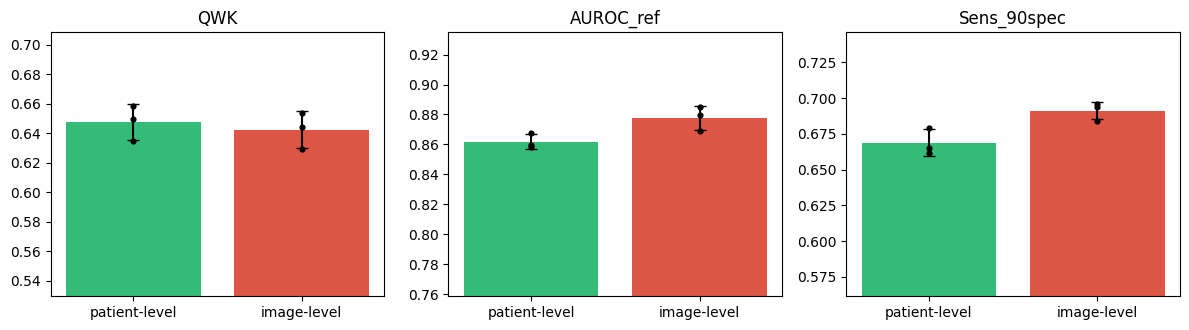

In [13]:
if RUN["leak"]:
    assert PATIENT_OK, "Patient IDs missing; RQ1 cannot be run."
    rows = []
    for sname, SPL in [("patient", SP), ("image", SI)]:
        for s in range(CFG["N_SEEDS"]):
            r = train_model(f"leak_{sname}_s{s}", "effb0", "ce", SPL["train"], {"val": SPL["val"], "test": SPL["test"]},
                            CFG["EPOCHS_LEAK"], seed=s, phase="1_leak")
            ev = get_eval(r, "test"); rows.append(dict(split=sname, seed=s, **metric_row(ev["P"], ev["pred"], ev["y"])))
    leak = pd.DataFrame(rows); save_table("phase1_leak_runs", leak, show=False)
    agg = leak.groupby("split")[["QWK", "AUROC_ref", "Sens_90spec", "ECE", "NLL"]].agg(["mean", "std"]).round(4)
    display(agg)

    # paired inflation estimate with patient-cluster bootstrap on each test set (seed 0)
    def qwk_of(ev): return lambda idx: qwk(ev["y"][idx], ev["pred"][idx])
    evp, evi = (get_eval(load_run(f"leak_{n}_s0"), "test") for n in ("patient", "image"))
    _, _, _, bp_ = cluster_boot(qwk_of(evp), evp["g"], CFG["N_BOOT"], 1); _, _, _, bi_ = cluster_boot(qwk_of(evi), evi["g"], CFG["N_BOOT"], 2)
    d = bi_[:min(len(bp_), len(bi_))] - bp_[:min(len(bp_), len(bi_))]
    mi = leak[leak.split == "image"].QWK.mean() - leak[leak.split == "patient"].QWK.mean()
    print(f"QWK inflation (image-level minus patient-level), mean over seeds: {mi:+.4f} | seed-0 bootstrap 95% CI [{np.percentile(d,2.5):+.4f}, {np.percentile(d,97.5):+.4f}]")
    print(f"{100*leak_frac:.1f}% of image-level test images have the patient's other eye (or the same eye) in train.")

    fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
    for a, m in zip(ax, ["QWK", "AUROC_ref", "Sens_90spec"]):
        for i, sname in enumerate(["patient", "image"]):
            v = leak[leak.split == sname][m]; a.bar(i, v.mean(), yerr=v.std(), color=["#3b7", "#d54"][i], capsize=4)
            a.scatter([i] * len(v), v, c="k", s=12, zorder=3)
        a.set_xticks([0, 1]); a.set_xticklabels(["patient-level", "image-level"]); a.set_title(m); a.set_ylim(max(0, leak[m].min() - .1), min(1, leak[m].max() + .05))
    plt.tight_layout(); plt.savefig(RES / "fig_leakage.png", dpi=150); plt.show()

## 8. Phase 2: Backbone x head grid (RQ3)
**Four backbones x three heads = 12 configs** under an identical recipe. Successive halving: all 12 get a short rung-1 run and the top `RUNG2_KEEP` by **validation** QWK go on to the full recipe. Selection never looks at test.

In [14]:
BEST = {}
if RUN["grid"]:
    backbones = [b for b in ["effb0", "effb3", "convnext_t", "dinov2_s"]]
    heads = ["ce", "reg", "corn"]
    evs = {"val": SP["val"], "test": SP["test"]}

    def val_qwk(r):
        ev = get_eval(r, "val"); return qwk(ev["y"], ev["pred"])

    r1 = []
    for bb in backbones:
        for hd in heads:
            r = train_model(f"g1_{bb}_{hd}", bb, hd, SP["train"], evs, CFG["EPOCHS_RUNG1"], seed=0, phase="2_grid_r1")
            r1.append(dict(backbone=bb, head=hd, val_QWK=val_qwk(r)))
    r1 = pd.DataFrame(r1).sort_values("val_QWK", ascending=False).reset_index(drop=True)
    save_table("phase2_rung1", r1)
    top = r1.head(CFG["RUNG2_KEEP"])

    r2 = []
    for _, row in top.iterrows():
        bb, hd = row.backbone, row["head"]
        r = train_model(f"g2_{bb}_{hd}_raw", bb, hd, SP["train"], evs, CFG["EPOCHS_GRID"], seed=0, phase="2_grid_r2")
        ev = get_eval(r, "test"); m = metric_row(ev["P"], ev["pred"], ev["y"])
        r2.append(dict(backbone=bb, head=hd, val_QWK=val_qwk(r), **m, recall=np.round(per_class_recall(ev["y"], ev["pred"]), 2).tolist()))
    r2 = pd.DataFrame(r2).sort_values("val_QWK", ascending=False).reset_index(drop=True)
    save_table("phase2_rung2", r2)
    b0 = r2.iloc[0]; BEST.update(bb=b0.backbone, head=b0["head"], pp="raw", tag=f"g2_{b0.backbone}_{b0['head']}_raw")
    print("Best config after rung 2 (by val QWK):", BEST)

[g1_effb0_ce] ep 1/3 loss 1.1065 val QWK 0.5107 (53s)
[g1_effb0_ce] ep 2/3 loss 0.9269 val QWK 0.6006 (105s)
[g1_effb0_ce] ep 3/3 loss 0.8367 val QWK 0.6165 (158s)
[g1_effb0_reg] ep 1/3 loss 0.4234 val QWK 0.5563 (53s)
[g1_effb0_reg] ep 2/3 loss 0.3133 val QWK 0.6020 (105s)
[g1_effb0_reg] ep 3/3 loss 0.2831 val QWK 0.6092 (158s)
[g1_effb0_corn] ep 1/3 loss 0.5221 val QWK 0.5526 (54s)
[g1_effb0_corn] ep 2/3 loss 0.4437 val QWK 0.6218 (107s)
[g1_effb0_corn] ep 3/3 loss 0.4076 val QWK 0.6237 (161s)


model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

[g1_effb3_ce] ep 1/3 loss 1.0934 val QWK 0.5754 (280s)
[g1_effb3_ce] ep 2/3 loss 0.8965 val QWK 0.6309 (379s)
[g1_effb3_ce] ep 3/3 loss 0.8098 val QWK 0.6474 (479s)
[g1_effb3_reg] ep 1/3 loss 0.4078 val QWK 0.5876 (99s)
[g1_effb3_reg] ep 2/3 loss 0.2935 val QWK 0.6517 (199s)
[g1_effb3_reg] ep 3/3 loss 0.2644 val QWK 0.6491 (298s)
[g1_effb3_corn] ep 1/3 loss 0.5111 val QWK 0.5561 (101s)
[g1_effb3_corn] ep 2/3 loss 0.4237 val QWK 0.6495 (202s)
[g1_effb3_corn] ep 3/3 loss 0.3834 val QWK 0.6516 (302s)


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

...

[g1_dinov2_s_ce] ep 1/3 loss 1.4883 val QWK 0.0000 (103s)
[g1_dinov2_s_ce] ep 2/3 loss 1.3876 val QWK 0.0081 (204s)
[g1_dinov2_s_ce] ep 3/3 loss 1.3627 val QWK 0.0075 (306s)
[g1_dinov2_s_reg] ep 1/3 loss 0.7555 val QWK 0.0969 (102s)
[g1_dinov2_s_reg] ep 2/3 loss 0.6709 val QWK 0.0042 (203s)
[g1_dinov2_s_reg] ep 3/3 loss 0.6530 val QWK 0.0100 (304s)
[g1_dinov2_s_corn] ep 1/3 loss 0.7096 val QWK 0.0000 (103s)
[g1_dinov2_s_corn] ep 2/3 loss 0.6677 val QWK 0.0058 (205s)
[g1_dinov2_s_corn] ep 3/3 loss 0.6600 val QWK 0.0102 (307s)


,backbone,head,val_QWK
0,convnext_t,corn,0.698913
1,convnext_t,ce,0.691475
2,convnext_t,reg,0.690343
3,effb3,reg,0.683179
4,effb0,reg,0.656671
5,effb3,corn,0.651586
6,effb3,ce,0.647383
7,effb0,corn,0.623726
8,effb0,ce,0.616495
9,dinov2_s,reg,0.104644


[g2_convnext_t_corn_raw] ep 1/10 loss 0.5514 val QWK 0.5569 (112s)
[g2_convnext_t_corn_raw] ep 2/10 loss 0.4794 val QWK 0.5611 (223s)
[g2_convnext_t_corn_raw] ep 3/10 loss 0.4576 val QWK 0.6325 (334s)
[g2_convnext_t_corn_raw] ep 4/10 loss 0.4331 val QWK 0.6867 (446s)
[g2_convnext_t_corn_raw] ep 5/10 loss 0.4084 val QWK 0.6611 (557s)
[g2_convnext_t_corn_raw] ep 6/10 loss 0.3817 val QWK 0.6866 (669s)
[g2_convnext_t_corn_raw] ep 7/10 loss 0.3493 val QWK 0.6982 (780s)
[g2_convnext_t_corn_raw] ep 8/10 loss 0.3185 val QWK 0.7146 (892s)
[g2_convnext_t_corn_raw] ep 9/10 loss 0.3036 val QWK 0.7286 (1004s)
[g2_convnext_t_corn_raw] ep 10/10 loss 0.2871 val QWK 0.7216 (1115s)
[g2_convnext_t_ce_raw] ep 1/10 loss 1.1772 val QWK 0.6114 (110s)
[g2_convnext_t_ce_raw] ep 2/10 loss 0.9963 val QWK 0.6338 (221s)
[g2_convnext_t_ce_raw] ep 3/10 loss 0.9471 val QWK 0.6674 (331s)
[g2_convnext_t_ce_raw] ep 4/10 loss 0.8938 val QWK 0.6515 (442s)
[g2_convnext_t_ce_raw] ep 5/10 loss 0.8420 val QWK 0.6988 (552s)
[g

,backbone,head,val_QWK,QWK,AUROC_ref,Sens_90spec,Sens_95spec,ECE,NLL,Brier,AURC,QWK_80cov,recall
0,convnext_t,reg,0.751003,0.740660,0.903459,0.770133,0.703675,0.177861,0.866803,0.463158,0.016901,0.602187,"[0.92, 0.13, 0.28, 0.39, 0.71]"
1,convnext_t,corn,0.728629,0.725897,0.909932,0.763096,0.704457,0.048773,0.681619,0.337900,0.020476,0.785337,"[0.83, 0.26, 0.4, 0.46, 0.59]"
2,convnext_t,ce,0.715609,0.719838,0.904839,0.763878,0.698202,0.052455,0.671439,0.334561,0.021821,0.788711,"[0.84, 0.27, 0.42, 0.44, 0.49]"
3,effb3,reg,0.705163,0.691798,0.870136,0.701329,0.618452,0.176672,0.891358,0.471246,0.020344,0.379240,"[0.9, 0.14, 0.25, 0.49, 0.46]"
4,effb0,reg,0.691202,0.684763,0.851997,0.677873,0.615324,0.189704,0.898338,0.484144,0.021988,0.417936,"[0.88, 0.14, 0.22, 0.26, 0.66]"


Best config after rung 2 (by val QWK): {'bb': 'convnext_t', 'head': 'reg', 'pp': 'raw', 'tag': 'g2_convnext_t_reg_raw'}


In [15]:
# Preprocessing ablation on the best config: raw vs Ben Graham vs CLAHE
if RUN["grid"]:
    pp_rows = [dict(preproc="raw", val_QWK=val_qwk(load_run(BEST["tag"])), tag=BEST["tag"])]
    for pp in ["ben", "clahe"]:
        tag = f"g2_{BEST['bb']}_{BEST['head']}_{pp}"
        r = train_model(tag, BEST["bb"], BEST["head"], SP["train"], evs, CFG["EPOCHS_GRID"], seed=0, preproc=pp, phase="2_preproc")
        pp_rows.append(dict(preproc=pp, val_QWK=val_qwk(r), tag=tag))
    ppdf = pd.DataFrame(pp_rows)
    for i, row in ppdf.iterrows():
        ev = get_eval(load_run(row.tag), "test"); ppdf.loc[i, "test_QWK"] = qwk(ev["y"], ev["pred"])
        ppdf.loc[i, "AUROC_ref"] = roc_auc_score(ev["y"] >= 2, ev["P"][:, 2:].sum(1))
    save_table("phase2_preproc", ppdf.drop(columns="tag"))
    win = ppdf.sort_values("val_QWK", ascending=False).iloc[0]
    BEST.update(pp=win.preproc, tag=win.tag)
    print("Final recipe:", BEST)
    json.dump(BEST, open(RES / "best_config.json", "w"))
elif (RES / "best_config.json").exists():
    BEST = json.load(open(RES / "best_config.json"))

[g2_convnext_t_reg_ben] ep 1/10 loss 0.4710 val QWK 0.5738 (119s)
[g2_convnext_t_reg_ben] ep 2/10 loss 0.3523 val QWK 0.6030 (238s)
[g2_convnext_t_reg_ben] ep 3/10 loss 0.3237 val QWK 0.6414 (357s)
[g2_convnext_t_reg_ben] ep 4/10 loss 0.3007 val QWK 0.6719 (475s)
[g2_convnext_t_reg_ben] ep 5/10 loss 0.2802 val QWK 0.6734 (594s)
[g2_convnext_t_reg_ben] ep 6/10 loss 0.2655 val QWK 0.6825 (713s)
[g2_convnext_t_reg_ben] ep 7/10 loss 0.2372 val QWK 0.6980 (832s)
[g2_convnext_t_reg_ben] ep 8/10 loss 0.2209 val QWK 0.7187 (951s)
[g2_convnext_t_reg_ben] ep 9/10 loss 0.2119 val QWK 0.7240 (1070s)
[g2_convnext_t_reg_ben] ep 10/10 loss 0.2116 val QWK 0.7252 (1189s)
[g2_convnext_t_reg_clahe] ep 1/10 loss 0.4596 val QWK 0.5580 (110s)
[g2_convnext_t_reg_clahe] ep 2/10 loss 0.3552 val QWK 0.5902 (220s)
[g2_convnext_t_reg_clahe] ep 3/10 loss 0.3282 val QWK 0.5738 (330s)
[g2_convnext_t_reg_clahe] ep 4/10 loss 0.3037 val QWK 0.6573 (440s)
[g2_convnext_t_reg_clahe] ep 5/10 loss 0.2812 val QWK 0.6748 (551

,preproc,val_QWK,test_QWK,AUROC_ref
0,raw,0.751003,0.740660,0.903459
1,ben,0.743101,0.730007,0.905332
2,clahe,0.739537,0.732935,0.895026


Final recipe: {'bb': 'convnext_t', 'head': 'reg', 'pp': 'raw', 'tag': 'g2_convnext_t_reg_raw'}


## 9. Phase 3: Uncertainty methods (RQ3)
The four methods on the best backbone/head, on the same patient-level test set:
1. **Temperature scaling** (T fit on validation NLL, applied to log-probabilities)
2. **Deep ensemble** (5 seeds, mean of probabilities)
3. **MC-dropout** (T=20 stochastic head passes; dropout is in the head only, which is a stated limitation)
4. **Evidential** (Dirichlet head, EDL loss)

Uncertainty score for selective prediction is predictive entropy. The evidential model also gets a vacuity score K/S. Uncalibrated single model = baseline. All methods use rounded expected grade as the prediction so only the probabilities differ.

In [16]:
PM = {}
def fit_temp(P, y_):
    lp = np.log(np.clip(P, 1e-9, 1))
    f = lambda lt: nll_score(softmax_np(lp / np.exp(lt)), y_)
    return float(np.exp(minimize_scalar(f, bounds=(-2, 2), method="bounded").x))

def temp_apply(P, T): return softmax_np(np.log(np.clip(P, 1e-9, 1)) / T)

def mc_run(tag, T):
    r = load_run(tag); m = load_model(tag); pp = str(r["preproc"]); X = get_X(pp); head = str(r["head"]); out = {}
    for sp in ("val", "test"):
        o = predict_mc(m, X, SP[sp], y, pp, T)
        out[sp] = to_probs(o, head, float(r["sigma"])).mean(0)
    del m; torch.cuda.empty_cache(); return out

if RUN["unc"]:
    bb, hd, pp = BEST["bb"], BEST["head"], BEST["pp"]
    members = [BEST["tag"]]
    for s in range(1, CFG["ENS_N"]):
        tag = f"m_{bb}_{hd}_{pp}_s{s}"
        train_model(tag, bb, hd, SP["train"], evs, CFG["EPOCHS_GRID"], seed=s, preproc=pp, phase="3_ens"); members.append(tag)
    evid_tag = f"m_{bb}_evid_{pp}_s0"
    train_model(evid_tag, bb, "evid", SP["train"], evs, CFG["EPOCHS_GRID"], seed=0, preproc=pp, phase="3_evid")

    yv, yt = y[SP["val"]], y[SP["test"]]
    base = load_run(members[0]); Pv0, Pt0 = get_eval(base, "val")["P"], get_eval(base, "test")["P"]
    PM["Baseline (single, uncalibrated)"] = dict(val=Pv0, test=Pt0)
    T = fit_temp(Pv0, yv); print(f"Temperature T = {T:.3f}")
    PM["Temperature scaling"] = dict(val=temp_apply(Pv0, T), test=temp_apply(Pt0, T))
    ens_v = np.mean([get_eval(load_run(t), "val")["P"] for t in members], 0)
    ens_t = np.mean([get_eval(load_run(t), "test")["P"] for t in members], 0)
    PM[f"Deep ensemble (x{len(members)})"] = dict(val=ens_v, test=ens_t)
    mc = mc_run(members[0], CFG["MC_T"]); PM[f"MC-dropout (T={CFG['MC_T']})"] = dict(val=mc["val"], test=mc["test"])
    ev_r = load_run(evid_tag); PM["Evidential (Dirichlet)"] = dict(val=get_eval(ev_r, "val")["P"], test=get_eval(ev_r, "test")["P"])
    PM["Evidential (Dirichlet)"]["unc_test"] = K / (np.logaddexp(0, ev_r["out_test"]) + 1).sum(1)   # vacuity K/S

    gt = pat[SP["test"]]; rows = []
    def add_row(name, P, unc=None, label=None):
        pred = np.clip(np.rint(P @ np.arange(K)), 0, 4).astype(int); m = metric_row(P, pred, yt, unc)
        ci = {k: ci_str(f, gt, min(CFG["N_BOOT"], 200)) for k, f in [
            ("QWK", lambda i: qwk(yt[i], pred[i])), ("ECE", lambda i: ece_score(P[i], yt[i])),
            ("AURC", lambda i: aurc((entropy(P) if unc is None else unc)[i], (yt[i] - pred[i]) ** 2 / 16.))]}
        rows.append(dict(method=label or name, **{k: round(v, 4) for k, v in m.items()}, **{f"{k}_CI": v for k, v in ci.items()}))
    for name, d in PM.items(): add_row(name, d["test"])
    add_row("Evidential (Dirichlet)", PM["Evidential (Dirichlet)"]["test"], PM["Evidential (Dirichlet)"]["unc_test"], "Evidential, vacuity score")
    unc_df = pd.DataFrame(rows); save_table("phase3_uncertainty", unc_df)

    # 3-seed mean +- std of the single best model (key-model seeds)
    ss = []
    for t in members[:CFG["N_SEEDS"]]:
        e = get_eval(load_run(t), "test"); ss.append(metric_row(e["P"], e["pred"], e["y"]))
    ss = pd.DataFrame(ss); print("Best config over", CFG["N_SEEDS"], "seeds (mean +- std):")
    display(pd.DataFrame({"mean": ss.mean().round(4), "std": ss.std().round(4)}).T)

[m_convnext_t_reg_raw_s1] ep 1/10 loss 0.4733 val QWK 0.5711 (110s)
[m_convnext_t_reg_raw_s1] ep 2/10 loss 0.3637 val QWK 0.5444 (221s)
[m_convnext_t_reg_raw_s1] ep 3/10 loss 0.3272 val QWK 0.6245 (331s)
[m_convnext_t_reg_raw_s1] ep 4/10 loss 0.3005 val QWK 0.6644 (440s)
[m_convnext_t_reg_raw_s1] ep 5/10 loss 0.2785 val QWK 0.6696 (551s)
[m_convnext_t_reg_raw_s1] ep 6/10 loss 0.2607 val QWK 0.6915 (661s)
[m_convnext_t_reg_raw_s1] ep 7/10 loss 0.2347 val QWK 0.7149 (771s)
[m_convnext_t_reg_raw_s1] ep 8/10 loss 0.2204 val QWK 0.7240 (881s)
[m_convnext_t_reg_raw_s1] ep 9/10 loss 0.2094 val QWK 0.7289 (991s)
[m_convnext_t_reg_raw_s1] ep 10/10 loss 0.2079 val QWK 0.7313 (1101s)
[m_convnext_t_reg_raw_s2] ep 1/10 loss 0.4707 val QWK 0.5984 (110s)
[m_convnext_t_reg_raw_s2] ep 2/10 loss 0.3605 val QWK 0.5988 (220s)
[m_convnext_t_reg_raw_s2] ep 3/10 loss 0.3342 val QWK 0.5269 (331s)
[m_convnext_t_reg_raw_s2] ep 4/10 loss 0.3043 val QWK 0.6708 (440s)
[m_convnext_t_reg_raw_s2] ep 5/10 loss 0.2764 

,method,QWK,AUROC_ref,Sens_90spec,Sens_95spec,ECE,NLL,Brier,AURC,QWK_80cov,QWK_CI,ECE_CI,AURC_CI
0,"Baseline (single, uncalibrated)",0.7105,0.9035,0.7701,0.7037,0.1779,0.8668,0.4632,0.0175,0.5794,"0.710 [0.689, 0.730]","0.178 [0.169, 0.187]","0.018 [0.015, 0.020]"
1,Temperature scaling,0.7105,0.9035,0.7701,0.7037,0.1779,0.8668,0.4632,0.0175,0.5794,"0.710 [0.689, 0.730]","0.178 [0.169, 0.187]","0.018 [0.015, 0.020]"
2,Deep ensemble (x5),0.7195,0.9155,0.7881,0.7193,0.2111,0.8260,0.4539,0.0143,0.5673,"0.719 [0.699, 0.739]","0.211 [0.201, 0.221]","0.014 [0.013, 0.016]"
3,MC-dropout (T=20),0.7097,0.9041,0.7709,0.7045,0.1777,0.8658,0.4630,0.0171,0.5769,"0.710 [0.687, 0.729]","0.178 [0.167, 0.187]","0.017 [0.015, 0.020]"
4,Evidential (Dirichlet),0.6210,0.9092,0.7748,0.7005,0.1079,0.6941,0.3301,0.0256,0.6667,"0.621 [0.599, 0.644]","0.108 [0.098, 0.118]","0.026 [0.022, 0.030]"
5,"Evidential, vacuity score",0.6210,0.9092,0.7748,0.7005,0.1079,0.6941,0.3301,0.0256,0.6684,"0.621 [0.599, 0.644]","0.108 [0.098, 0.118]","0.026 [0.022, 0.030]"


Best config over 3 seeds (mean +- std):


,QWK,AUROC_ref,Sens_90spec,Sens_95spec,ECE,NLL,Brier,AURC,QWK_80cov
mean,0.7411,0.9051,0.7756,0.6987,0.1791,0.8645,0.4619,0.0162,0.592
std,0.0020,0.0016,0.0064,0.0044,0.0054,0.0047,0.0069,0.0010,0.009


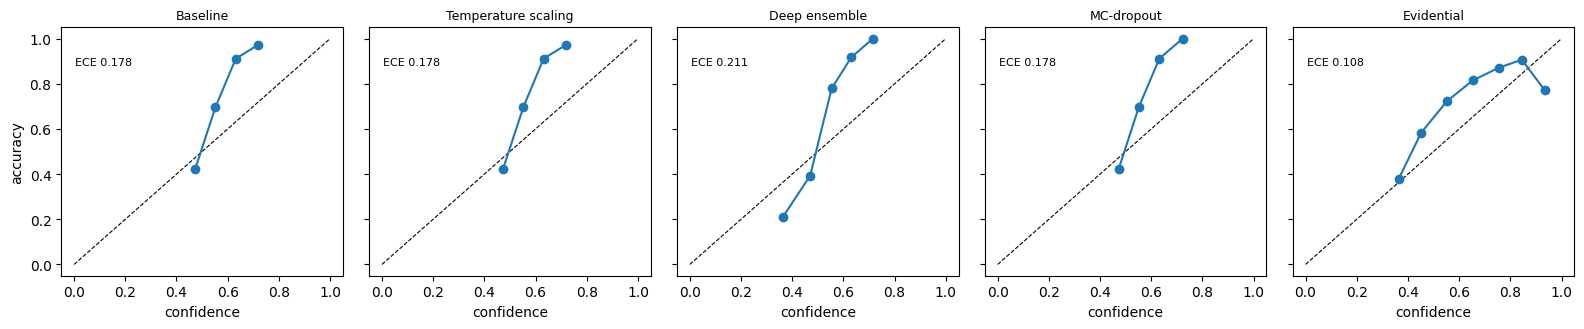

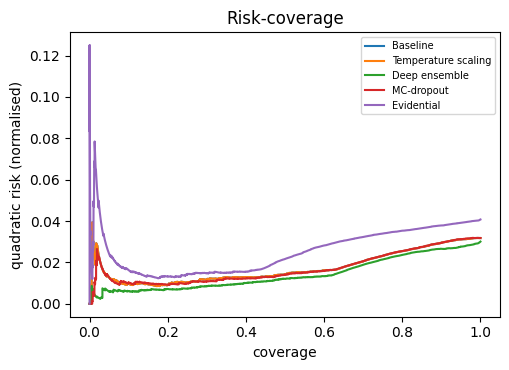

In [17]:
if RUN["unc"]:
    fig, ax = plt.subplots(1, len(PM), figsize=(3.2 * len(PM), 3.4), sharey=True)
    for a, (name, d) in zip(ax, PM.items()):
        P = d["test"]; conf, ok = P.max(1), (P.argmax(1) == yt)
        e = np.linspace(0, 1, 11); xs, ys = [], []
        for lo, hi in zip(e[:-1], e[1:]):
            m = (conf > lo) & (conf <= hi)
            if m.sum() > 20: xs.append(conf[m].mean()); ys.append(ok[m].mean())
        a.plot([0, 1], [0, 1], "k--", lw=.8); a.plot(xs, ys, "o-"); a.set_title(name.split("(")[0].strip(), fontsize=9)
        a.set_xlabel("confidence"); a.text(.05, .85, f"ECE {ece_score(P, yt):.3f}", transform=a.transAxes, fontsize=8)
    ax[0].set_ylabel("accuracy"); plt.tight_layout(); plt.savefig(RES / "fig_reliability.png", dpi=150); plt.show()

    plt.figure(figsize=(5.2, 3.8))
    for name, d in PM.items():
        P = d["test"]; pred = np.clip(np.rint(P @ np.arange(K)), 0, 4).astype(int)
        cov, risk = risk_coverage(entropy(P), (yt - pred) ** 2 / 16.); plt.plot(cov, risk, label=name.split("(")[0].strip())
    plt.xlabel("coverage"); plt.ylabel("quadratic risk (normalised)"); plt.legend(fontsize=7); plt.title("Risk-coverage")
    plt.tight_layout(); plt.savefig(RES / "fig_risk_coverage.png", dpi=150); plt.show()

## 10. Phase 4: Ordinal conformal risk control (RQ4, main contribution)
Calibrate on the validation split, evaluate on the held-out patient-level test split. The **main method is chosen by validation NLL**, not by test. A non-conformal baseline (empirical sensitivity threshold on `P(y>=2)`) is shown for comparison. It has no guarantee.

Main method (lowest val NLL): Evidential (Dirichlet)


,alpha,q,FNR,referral_rate,spec_ref,avg_set_size,pct_singleton,within_alpha,naive_FNR,naive_referral
20,0.02,0.8992,0.0078,0.8576,0.1751,3.2045,0.0148,True,0.0094,0.8393
21,0.05,0.8726,0.0414,0.6713,0.3983,2.7182,0.0598,True,0.0461,0.6576
22,0.10,0.8357,0.0860,0.4741,0.6324,2.2228,0.2103,True,0.0860,0.4737
23,0.15,0.8000,0.1360,0.3521,0.7719,1.9520,0.3296,True,0.1376,0.3489
24,0.20,0.7460,0.1994,0.2579,0.8736,1.6927,0.4726,True,0.2017,0.2555


,alpha,FNR,CI95,n_referable_test
0,0.02,0.0078,"[0.0039, 0.0141]",1279
1,0.05,0.0414,"[0.0297, 0.0547]",1279
2,0.10,0.0860,"[0.0689, 0.1035]",1279
3,0.15,0.1360,"[0.1155, 0.1576]",1279
4,0.20,0.1994,"[0.1782, 0.2220]",1279


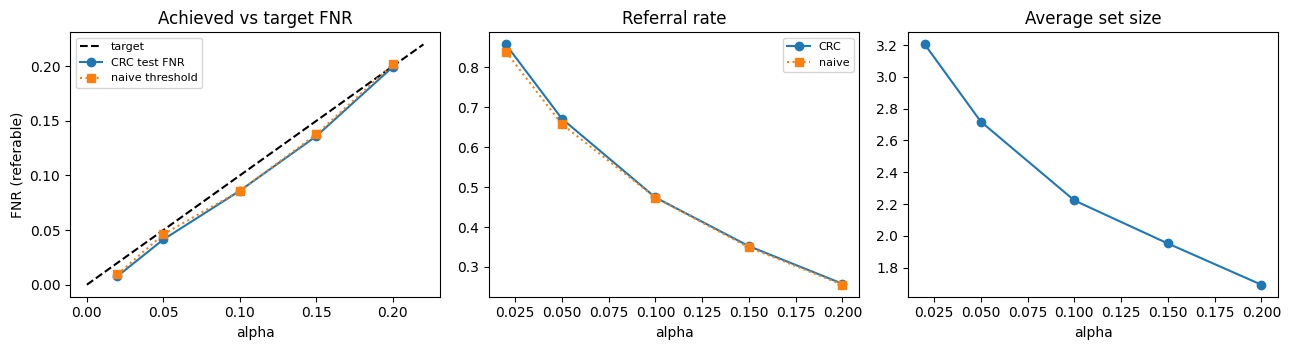

All uncertainty methods at alpha = 0.05:


,method,FNR,referral_rate,avg_set_size,within_alpha
1,"Baseline (single, uncalibrated)",0.0344,0.7134,2.7871,True
6,Temperature scaling,0.0344,0.7134,2.7871,True
11,Deep ensemble (x5),0.0352,0.6537,2.7476,True
16,MC-dropout (T=20),0.0313,0.7247,2.8040,True
21,Evidential (Dirichlet),0.0414,0.6713,2.7182,True


In [18]:
if RUN["conformal"]:
    ALPHAS = CFG["ALPHAS"]; crow = []
    for name, d in PM.items():
        Pv, Pt = d["val"], d["test"]; sv = crc_scores(Pv)[yv >= 2]
        for a in ALPHAS:
            q = calibrate_q(sv, a); ce = conformal_eval(Pt, yt, q)
            thr = np.quantile(Pv[yv >= 2, 2:].sum(1), a); refer = Pt[:, 2:].sum(1) >= thr
            crow.append(dict(method=name, alpha=a, q=round(q, 4), **{k: round(v, 4) for k, v in ce.items()}, within_alpha=ce["FNR"] <= a,
                             naive_FNR=round(float((~refer[yt >= 2]).mean()), 4), naive_referral=round(float(refer.mean()), 4)))
    cdf = pd.DataFrame(crow); save_table("phase4_conformal", cdf, show=False)
    MAIN = min(PM, key=lambda n: nll_score(PM[n]["val"], yv)); print("Main method (lowest val NLL):", MAIN)
    display(cdf[cdf.method == MAIN].drop(columns="method"))

    # CI on FNR for the main method
    Pm = PM[MAIN]; sv = crc_scores(Pm["val"])[yv >= 2]; refm = (yt >= 2); gref = gt[refm]
    ci_rows = []
    for a in ALPHAS:
        q = calibrate_q(sv, a); S = ordinal_sets(Pm["test"], q)[refm][:, 2:].any(1)
        p_, lo_, hi_, _ = cluster_boot(lambda i: float((~S[i]).mean()), gref, CFG["N_BOOT"], 3)
        ci_rows.append(dict(alpha=a, FNR=round(p_, 4), CI95=f"[{lo_:.4f}, {hi_:.4f}]", n_referable_test=int(refm.sum())))
    display(pd.DataFrame(ci_rows))

    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6)); m = cdf[cdf.method == MAIN]
    ax[0].plot([0, .22], [0, .22], "k--", label="target"); ax[0].plot(m.alpha, m.FNR, "o-", label="CRC test FNR"); ax[0].plot(m.alpha, m.naive_FNR, "s:", label="naive threshold")
    ax[0].set_xlabel("alpha"); ax[0].set_ylabel("FNR (referable)"); ax[0].legend(fontsize=8); ax[0].set_title("Achieved vs target FNR")
    ax[1].plot(m.alpha, m.referral_rate, "o-", label="CRC"); ax[1].plot(m.alpha, m.naive_referral, "s:", label="naive"); ax[1].set_xlabel("alpha"); ax[1].set_title("Referral rate"); ax[1].legend(fontsize=8)
    ax[2].plot(m.alpha, m.avg_set_size, "o-"); ax[2].set_xlabel("alpha"); ax[2].set_title("Average set size")
    plt.tight_layout(); plt.savefig(RES / "fig_conformal.png", dpi=150); plt.show()

    ms = cdf[cdf.alpha == CFG["ALPHA_MAIN"]][["method", "FNR", "referral_rate", "avg_set_size", "within_alpha"]]
    print(f"All uncertainty methods at alpha = {CFG['ALPHA_MAIN']}:"); display(ms)

In [19]:
# Validity over many random calibration/test draws. Pool val+test, split patients 50/50 each time, calibrate on one eye per
# patient (keeps calibration points independent), test on all referable images of held-out patients.
if RUN["conformal"]:
    pool = np.concatenate([SP["val"], SP["test"]]); Pp = np.vstack([Pm["val"], Pm["test"]]); yp, gp = y[pool], pat[pool]
    sp_ = crc_scores(Pp); rng = np.random.default_rng(7); ug = np.unique(gp); recs = []
    for rep in range(200):
        half = set(rng.permutation(ug)[: len(ug) // 2]); incal = np.array([g in half for g in gp])
        cal = np.flatnonzero(incal & (yp >= 2)); cal = cal[rng.permutation(len(cal))]
        _, first = np.unique(gp[cal], return_index=True); cal = cal[first]
        tst = np.flatnonzero(~incal & (yp >= 2))
        for a in ALPHAS:
            q = calibrate_q(sp_[cal], a); recs.append(dict(alpha=a, FNR=float((sp_[tst] >= q).mean())))
    rv = pd.DataFrame(recs).groupby("alpha").FNR.agg(mean="mean", p90=lambda s: s.quantile(.9), max="max").round(4)
    rv["frac_runs_FNR<=alpha"] = pd.DataFrame(recs).groupby("alpha").apply(lambda g: (g.FNR <= g.name).mean()).round(3)
    rv = rv.reset_index(); save_table("phase4_validity_200_splits", rv)
    print("The guarantee is on the expectation: the mean FNR should be at or below alpha, with run-to-run spread shown by p90 / max.")

,alpha,mean,p90,max,frac_runs_FNR<=alpha
0,0.02,0.0163,0.0248,0.0398,0.725
1,0.05,0.0404,0.0538,0.0759,0.840
2,0.10,0.0822,0.1026,0.1274,0.880
3,0.15,0.1283,0.1532,0.1823,0.885
4,0.20,0.1747,0.2007,0.2244,0.890


The guarantee is on the expectation: the mean FNR should be at or below alpha, with run-to-run spread shown by p90 / max.


## 11. Phase 5: Label noise audit and noise-aware training (RQ2)
5-fold patient-grouped out-of-fold predictions on the training portion, then `cleanlab`. The validation and test labels are never edited, so the evaluation is not circular.

[oof_f0] ep 1/5 loss 1.1311 val QWK 0.4995 (87s)
[oof_f0] ep 2/5 loss 0.9607 val QWK 0.5470 (130s)
[oof_f0] ep 3/5 loss 0.8539 val QWK 0.6158 (172s)
[oof_f0] ep 4/5 loss 0.7594 val QWK 0.6169 (215s)
[oof_f0] ep 5/5 loss 0.7040 val QWK 0.6200 (257s)
[oof_f1] ep 1/5 loss 1.1291 val QWK 0.5031 (89s)
[oof_f1] ep 2/5 loss 0.9555 val QWK 0.6007 (133s)
[oof_f1] ep 3/5 loss 0.8488 val QWK 0.6256 (175s)
[oof_f1] ep 4/5 loss 0.7493 val QWK 0.6130 (217s)
[oof_f1] ep 5/5 loss 0.6848 val QWK 0.5996 (260s)
[oof_f2] ep 1/5 loss 1.1336 val QWK 0.5451 (82s)
[oof_f2] ep 2/5 loss 0.9695 val QWK 0.6168 (125s)
[oof_f2] ep 3/5 loss 0.8646 val QWK 0.6362 (167s)
[oof_f2] ep 4/5 loss 0.7681 val QWK 0.6102 (210s)
[oof_f2] ep 5/5 loss 0.7164 val QWK 0.6190 (252s)
[oof_f3] ep 1/5 loss 1.1333 val QWK 0.5675 (90s)
[oof_f3] ep 2/5 loss 0.9572 val QWK 0.5868 (132s)
[oof_f3] ep 3/5 loss 0.8418 val QWK 0.6134 (175s)
[oof_f3] ep 4/5 loss 0.7313 val QWK 0.6415 (217s)
[oof_f3] ep 5/5 loss 0.6729 val QWK 0.6297 (260s)
[oof

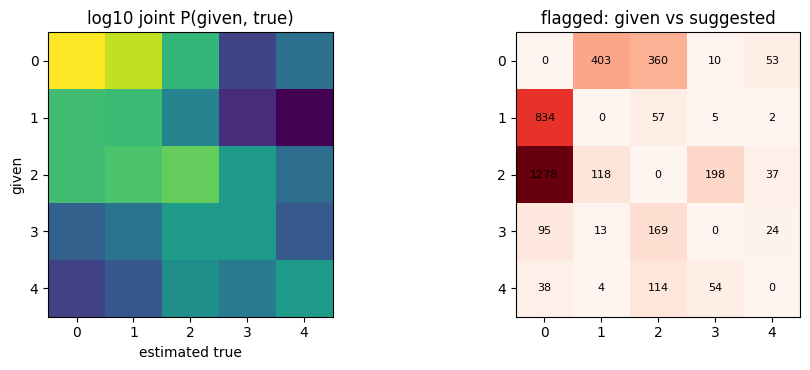

For 3866 flagged images with a labelled fellow eye, the cleanlab suggestion is closer to the fellow eye's grade in 20.1% of cases.


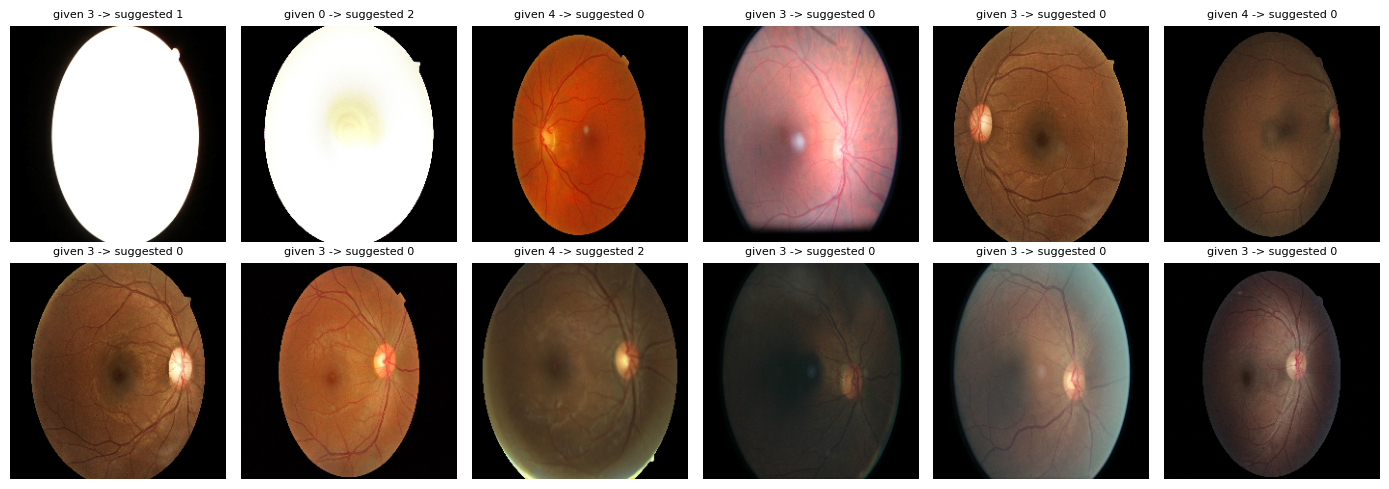

In [20]:
NOISE = {}
if RUN["noise"]:
    tr_idx = SP["train"]; folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=CFG["SEED"]).split(tr_idx, y[tr_idx], groups=pat[tr_idx]))
    oof_p = OUT / "oof.npy"
    if not oof_p.exists():
        oof = np.zeros((len(tr_idx), K))
        for f, (a, b) in enumerate(folds):
            r = train_model(f"oof_f{f}", "effb0", "ce", tr_idx[a], {"hold": tr_idx[b], "val": SP["val"]}, CFG["EPOCHS_OOF"], seed=f, phase="5_oof")
            oof[b] = to_probs(r["out_hold"], "ce")
        np.save(oof_p, oof)
    oof = np.load(oof_p); ytr_ = y[tr_idx]
    print(f"OOF accuracy {np.mean(oof.argmax(1)==ytr_):.3f} | OOF QWK {qwk(ytr_, np.clip(np.rint(oof@np.arange(K)),0,4).astype(int)):.3f}")

    from cleanlab.filter import find_label_issues
    from cleanlab.count import compute_confident_joint, estimate_joint
    flag = find_label_issues(labels=ytr_, pred_probs=oof, return_indices_ranked_by="self_confidence")
    sugg = oof.argmax(1); fl = np.zeros(len(tr_idx), bool); fl[flag] = True
    adj = np.mean(np.abs(sugg[fl] - ytr_[fl]) == 1) if fl.any() else np.nan
    print(f"Flagged {fl.sum()} / {len(fl)} training labels ({100*fl.mean():.1f}%) | {100*adj:.1f}% of flagged differ from the suggested grade by exactly 1")
    cj = compute_confident_joint(ytr_, oof); joint = estimate_joint(ytr_, oof, confident_joint=cj)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
    ax[0].imshow(np.log10(joint + 1e-6), cmap="viridis"); ax[0].set_title("log10 joint P(given, true)"); ax[0].set_xlabel("estimated true"); ax[0].set_ylabel("given")
    fb = pd.crosstab(pd.Series(ytr_[fl], name="given"), pd.Series(sugg[fl], name="suggested")).reindex(index=range(K), columns=range(K), fill_value=0)
    ax[1].imshow(fb.values, cmap="Reds"); ax[1].set_title("flagged: given vs suggested")
    for i in range(K):
        for j in range(K): ax[1].text(j, i, fb.values[i, j], ha="center", va="center", fontsize=8)
    plt.tight_layout(); plt.savefig(RES / "fig_noise_matrix.png", dpi=150); plt.show()

    # Do suggested labels move towards the fellow eye's label? (DR is strongly bilateral)
    other = df.set_index(["patient", "eye"]).label
    def fellow(i):
        e = df.eye.iloc[i]; 
        if e not in ("left", "right"): return np.nan
        k = (df.patient.iloc[i], "right" if e == "left" else "left")
        return other.get(k, np.nan) if k in other.index else np.nan
    fe = np.array([fellow(i) for i in tr_idx[fl]], float); ok = ~np.isnan(fe)
    if ok.sum() > 20:
        closer = np.mean(np.abs(sugg[fl][ok] - fe[ok]) < np.abs(ytr_[fl][ok] - fe[ok]))
        print(f"For {ok.sum()} flagged images with a labelled fellow eye, the cleanlab suggestion is closer to the fellow eye's grade in {100*closer:.1f}% of cases.")

    # Gallery of the most confident issues
    show = flag[:12]; fig, ax = plt.subplots(2, 6, figsize=(14, 5)); Xr = get_X("raw")
    for a, i in zip(ax.ravel(), show):
        a.imshow(Xr[tr_idx[i]]); a.set_title(f"given {ytr_[i]} -> suggested {sugg[i]}", fontsize=8); a.axis("off")
    plt.tight_layout(); plt.savefig(RES / "fig_noise_gallery.png", dpi=130); plt.show()

In [21]:
if RUN["noise"]:
    soft = np.zeros((len(df), K), np.float32); soft[SP["train"]] = (1 - CFG["SOFT_MIX"]) * np.eye(K)[ytr_] + CFG["SOFT_MIX"] * oof
    y_rel = y.copy(); y_rel[tr_idx[fl]] = sugg[fl]
    kept = tr_idx[~fl]; ev2 = {"val": SP["val"], "test": SP["test"]}
    variants = {"baseline": dict(idx=tr_idx), "drop_flagged": dict(idx=kept), "relabel": dict(idx=tr_idx, y_train=y_rel), "soft_labels": dict(idx=tr_idx, soft=soft)}
    NOISE = {}
    for v, kw in variants.items():
        tag = f"noise_{v}"; NOISE[v] = tag
        train_model(tag, "effb0", "ce", kw["idx"], ev2, CFG["EPOCHS_NOISE"], seed=0, y_train=kw.get("y_train"), soft=kw.get("soft"), phase="5_noise")
    nrow = []; evb = get_eval(load_run(NOISE["baseline"]), "test"); gb = evb["g"]
    for v, tag in NOISE.items():
        ev = get_eval(load_run(tag), "test"); m = metric_row(ev["P"], ev["pred"], ev["y"])
        _, lo_, hi_, _ = cluster_boot(lambda i: qwk(ev["y"][i], ev["pred"][i]) - qwk(evb["y"][i], evb["pred"][i]), gb, CFG["N_BOOT"], 5)
        nrow.append(dict(variant=v, n_train=len(variants[v]["idx"]), **{k: round(m[k], 4) for k in ["QWK", "AUROC_ref", "Sens_90spec", "ECE", "NLL"]},
                         dQWK_vs_baseline=f"[{lo_:+.4f}, {hi_:+.4f}]" if v != "baseline" else "-"))
    save_table("phase5_noise_test", pd.DataFrame(nrow))
    print("Test labels are the original (noisy) labels. The cleaner external set (Phase 6) is the fairer judge of noise-aware training.")

[noise_baseline] ep 1/8 loss 1.1317 val QWK 0.5524 (53s)
[noise_baseline] ep 2/8 loss 0.9638 val QWK 0.5936 (105s)
[noise_baseline] ep 3/8 loss 0.8924 val QWK 0.6270 (158s)
[noise_baseline] ep 4/8 loss 0.8090 val QWK 0.6348 (210s)
[noise_baseline] ep 5/8 loss 0.7297 val QWK 0.6307 (263s)
[noise_baseline] ep 6/8 loss 0.6525 val QWK 0.6285 (315s)
[noise_baseline] ep 7/8 loss 0.5860 val QWK 0.6113 (368s)
[noise_baseline] ep 8/8 loss 0.5544 val QWK 0.6210 (420s)
[noise_drop_flagged] ep 1/8 loss 0.8353 val QWK 0.5704 (44s)
[noise_drop_flagged] ep 2/8 loss 0.6027 val QWK 0.5821 (88s)
[noise_drop_flagged] ep 3/8 loss 0.4918 val QWK 0.5811 (132s)
[noise_drop_flagged] ep 4/8 loss 0.4031 val QWK 0.6073 (177s)
[noise_drop_flagged] ep 5/8 loss 0.3268 val QWK 0.6175 (221s)
[noise_drop_flagged] ep 6/8 loss 0.2647 val QWK 0.5831 (265s)
[noise_drop_flagged] ep 7/8 loss 0.2207 val QWK 0.5784 (309s)
[noise_drop_flagged] ep 8/8 loss 0.1988 val QWK 0.5712 (353s)
[noise_relabel] ep 1/8 loss 0.8732 val QWK 

,variant,n_train,QWK,AUROC_ref,Sens_90spec,ECE,NLL,dQWK_vs_baseline
0,baseline,23014,0.6499,0.8585,0.6654,0.0420,0.7278,-
1,drop_flagged,19148,0.6038,0.8588,0.6544,0.1556,1.2603,"[-0.0646, -0.0305]"
2,relabel,23014,0.6110,0.8508,0.6294,0.1182,0.9504,"[-0.0553, -0.0225]"
3,soft_labels,23014,0.5874,0.8700,0.6747,0.0240,0.7459,"[-0.0795, -0.0457]"


Test labels are the original (noisy) labels. The cleaner external set (Phase 6) is the fairer judge of noise-aware training.


## 12. Phase 6: External validation and domain shift (RQ5)
**APTOS 2019** is the minimum viable external set (Kaggle, add `aptos2019-blindness-detection` as input). Messidor-2 and IDRiD are optional. Fill in `CFG["MESSIDOR2"]` / `CFG["IDRID_ROOT"]` if you have access.
Fundus borders are cropped and external images are saved at the 224×224 source-cache size. `prep()` keeps the model input at `IMG=224` so the model matches the released image resolution. Check the sanity grid for a visual mismatch with EyePACS.

In [22]:
def prep_fundus(path, size=SRC_IMG):
    im = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    m = im.mean(2) > 10
    if m.sum() > 100:
        r, c = np.flatnonzero(m.sum(1) > max(5, 0.02 * im.shape[1])), np.flatnonzero(m.sum(0) > max(5, 0.02 * im.shape[0]))
        if len(r) and len(c): im = im[r[0]:r[-1] + 1, c[0]:c[-1] + 1]
    h, w = im.shape[:2]; s = max(h, w); pad = np.zeros((s, s, 3), np.uint8); pad[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = im
    return cv2.resize(pad, (size, size), interpolation=cv2.INTER_AREA)

def build_external(name, img_dir, csv, id_col, label_col, ext=".png", sep=","):
    xp, lp = CACHE / f"ext_{name}.npy", CACHE / f"ext_{name}.csv"
    if xp.exists(): return np.load(xp), pd.read_csv(lp)
    d = pd.read_csv(csv, sep=sep); d = d[[id_col, label_col]].dropna(); d.columns = ["id", "label"]
    d["label"] = d.label.astype(int); d = d[d.label.between(0, 4)].reset_index(drop=True)
    if CFG["DEBUG"]: d = d.sample(min(len(d), 300), random_state=0).reset_index(drop=True)
    paths = [os.path.join(img_dir, str(i) + ext) for i in d.id]
    with ThreadPoolExecutor(4) as ex_: arr = np.stack(list(tqdm(ex_.map(prep_fundus, paths), total=len(paths), desc=name)))
    np.save(xp, arr); d.to_csv(lp, index=False); return arr, d

EXT = {}
if RUN["external"]:
    ap_root = next((r for r, dd, ff in os.walk("/kaggle/input") if "train_images" in dd and "train.csv" in ff), None)
    if ap_root: EXT["aptos"] = build_external("aptos", f"{ap_root}/train_images", f"{ap_root}/train.csv", "id_code", "diagnosis")
    else: print("APTOS not found. Add the aptos2019-blindness-detection dataset as input.")
    if CFG["MESSIDOR2"]:
        m_ = CFG["MESSIDOR2"]; EXT["messidor2"] = build_external("messidor2", m_["img_dir"], m_["csv"], m_["id_col"], m_["label_col"], m_.get("ext", ".png"))
    if CFG["IDRID_ROOT"]:
        r_ = CFG["IDRID_ROOT"]
        EXT["idrid"] = build_external("idrid", f"{r_}/B. Disease Grading/1. Original Images/a. Training Set",
                                      f"{r_}/B. Disease Grading/2. Groundtruths/a. IDRiD_Disease Grading_Training Labels.csv", "Image name", "Retinopathy grade", ".jpg")
    for n, (Xe, de) in EXT.items(): print(n, Xe.shape, "grade counts:", np.bincount(de.label, minlength=5).tolist())
    if "aptos" in EXT:
        fig, ax = plt.subplots(2, 6, figsize=(14, 5)); Xe, de = EXT["aptos"]
        for a, i in zip(ax[0], np.random.default_rng(0).choice(len(Xe), 6, replace=False)): a.imshow(Xe[i]); a.set_title(f"APTOS grade {de.label[i]}", fontsize=8); a.axis("off")
        for a, i in zip(ax[1], np.random.default_rng(0).choice(SP["test"], 6, replace=False)): a.imshow(get_X("raw")[i]); a.set_title(f"EyePACS grade {y[i]}", fontsize=8); a.axis("off")
        plt.tight_layout(); plt.savefig(RES / "fig_domain_grid.png", dpi=120); plt.show()

APTOS not found. Add the aptos2019-blindness-detection dataset as input.


In [23]:
def ext_X(Xe, pp):
    if pp != "clahe": return Xe
    return np.stack([clahe_img(im) for im in Xe])

def member_probs(tag, Xe):
    r = load_run(tag); head, pp = str(r["head"]), str(r["preproc"]); m = load_model(tag)
    out = predict(m, ext_X(Xe, pp), np.arange(len(Xe)), np.zeros(len(Xe), np.int64), pp)
    del m; torch.cuda.empty_cache(); return to_probs(out, head, float(r["sigma"]))

if RUN["external"] and EXT and RUN["unc"]:
    Pv_src = PM[f"Deep ensemble (x{len(members)})"]["val"]; sv_src = crc_scores(Pv_src)[yv >= 2]
    Pt_src = PM[f"Deep ensemble (x{len(members)})"]["test"]
    ext_rows, shift_rows, EXT_P = [], [], {}
    for n, (Xe, de) in EXT.items():
        ye = de.label.values.astype(int)
        Pe = np.mean([member_probs(t, Xe) for t in members], 0); EXT_P[n] = Pe
        pred = np.clip(np.rint(Pe @ np.arange(K)), 0, 4).astype(int); m = metric_row(Pe, pred, ye)
        ext_rows.append(dict(dataset=n, N=len(ye), **{k: round(v, 4) for k, v in m.items()}))
        Pb = member_probs(members[0], Xe); pb = np.clip(np.rint(Pb @ np.arange(K)), 0, 4).astype(int)
        ext_rows.append(dict(dataset=n + " (single model)", N=len(ye), **{k: round(v, 4) for k, v in metric_row(Pb, pb, ye).items()}))
        # does the EyePACS-calibrated guarantee survive?
        for a in ALPHAS:
            q = calibrate_q(sv_src, a); ce = conformal_eval(Pe, ye, q)
            shift_rows.append(dict(dataset=n, alpha=a, q_source=round(q, 4), FNR_external=round(ce["FNR"], 4), within_alpha=ce["FNR"] <= a,
                                   referral_rate=round(ce["referral_rate"], 4), avg_set_size=round(ce["avg_set_size"], 3)))
    save_table("phase6_external_performance", pd.DataFrame(ext_rows))
    sdf = pd.DataFrame(shift_rows); save_table("phase6_guarantee_under_shift", sdf)

In [24]:
# Recalibration with ~200 target images, repeated over many random draws.
if RUN["external"] and EXT and RUN["unc"]:
    rng = np.random.default_rng(11); rr = []
    for n, (Xe, de) in EXT.items():
        ye = de.label.values.astype(int); Pe = EXT_P[n]; se = crc_scores(Pe); nrec = min(CFG["RECAL_N"], len(ye) // 2)
        for rep in range(200):
            perm = rng.permutation(len(ye)); cal, tst = perm[:nrec], perm[nrec:]
            ytst = ye[tst]; calref = cal[ye[cal] >= 2]
            for a in ALPHAS:
                for variant, sc in [("source q (no recal)", sv_src), ("target-only CRC", se[calref]), ("pooled source+target", np.concatenate([sv_src, se[calref]]))]:
                    q = calibrate_q(sc, a); ce = conformal_eval(Pe[tst], ytst, q)
                    rr.append(dict(dataset=n, variant=variant, alpha=a, FNR=ce["FNR"], referral=ce["referral_rate"], set_size=ce["avg_set_size"]))
    rr = pd.DataFrame(rr)
    agg = rr.groupby(["dataset", "variant", "alpha"]).agg(FNR_mean=("FNR", "mean"), FNR_p90=("FNR", lambda s: s.quantile(.9)),
                                                          referral=("referral", "mean"), set_size=("set_size", "mean")).round(4).reset_index()
    agg["frac_runs_within_alpha"] = rr.groupby(["dataset", "variant", "alpha"]).apply(lambda g: (g.FNR <= g.name[2]).mean()).round(3).values
    save_table("phase6_recalibration", agg, show=False); display(agg[agg.alpha == CFG["ALPHA_MAIN"]])
    for n in EXT:
        d = rr[(rr.dataset == n) & (rr.alpha == CFG["ALPHA_MAIN"])]
        plt.figure(figsize=(6, 3.6)); plt.boxplot([d[d.variant == v].FNR for v in d.variant.unique()], labels=[v.split(" (")[0] for v in d.variant.unique()])
        plt.axhline(CFG["ALPHA_MAIN"], c="r", ls="--"); plt.ylabel("FNR (referable)"); plt.title(f"{n}: FNR at alpha={CFG['ALPHA_MAIN']}, {nrec} target images")
        plt.tight_layout(); plt.savefig(RES / f"fig_recal_{n}.png", dpi=150); plt.show()

In [25]:
# Noise-aware variants on the cleaner external set
if RUN["external"] and EXT and RUN["noise"]:
    nr = []
    for n, (Xe, de) in EXT.items():
        ye = de.label.values.astype(int)
        for v, tag in NOISE.items():
            Pe = member_probs(tag, Xe); pred = np.clip(np.rint(Pe @ np.arange(K)), 0, 4).astype(int)
            nr.append(dict(dataset=n, variant=v, **{k: round(val, 4) for k, val in metric_row(Pe, pred, ye).items() if k in ["QWK", "AUROC_ref", "Sens_90spec", "ECE", "NLL"]}))
    save_table("phase6_noise_external", pd.DataFrame(nr))

## 13. Stretch: Grad-CAM and lesion pointing game
Works for CNN backbones (EfficientNet / ConvNeXt). The pointing game needs IDRiD lesion masks; set `CFG["IDRID_MASK_DIR"]` to a folder of binary masks named like the images. Without masks, the cell shows qualitative overlays only.

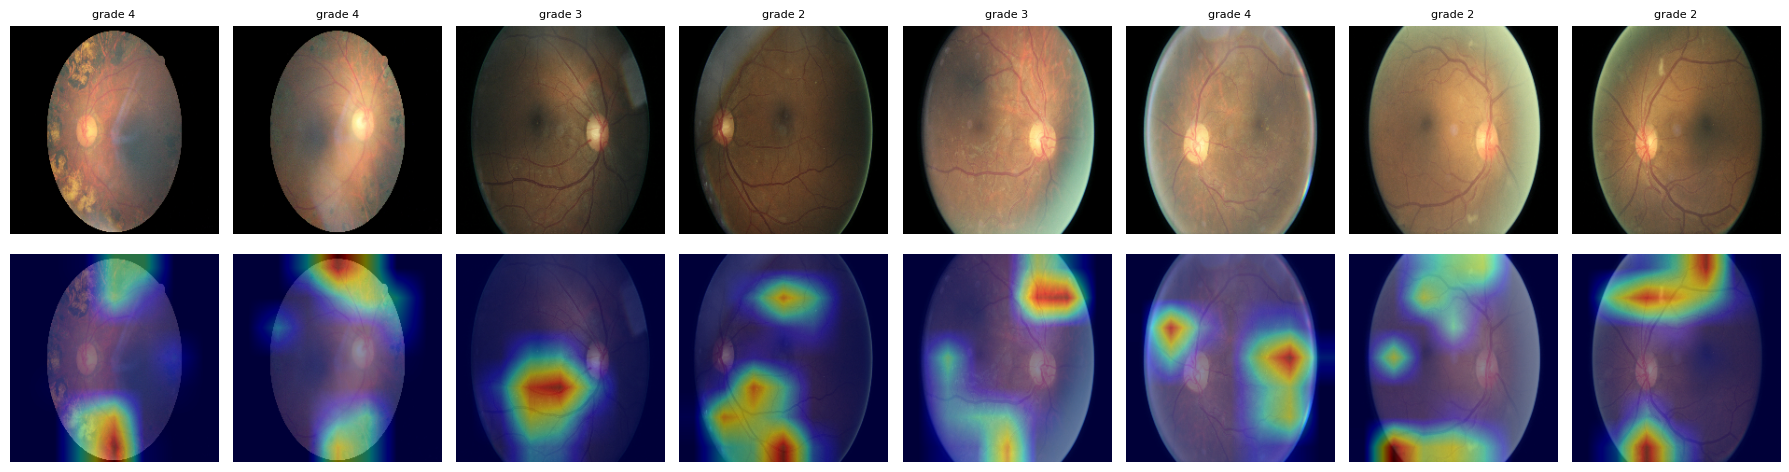

No lesion masks configured: qualitative Grad-CAM only.


In [26]:
def torch_ref_logscore(out, head, sigma):
    out = out.float()
    if head == "ce":   P = F.softmax(out, 1)
    elif head == "evid":
        a = F.softplus(out) + 1; P = a / a.sum(1, keepdim=True)
    elif head == "reg":
        r = out[:, :1]; P = F.softmax(-(r - torch.arange(K, device=out.device)) ** 2 / (2 * sigma ** 2), 1)
    elif head == "corn":
        S = torch.cumprod(torch.sigmoid(out), 1)
        P = torch.cat([1 - S[:, :1], S[:, :-1] - S[:, 1:], S[:, -1:]], 1).clamp_min(1e-9)
    return torch.log(P[:, 2:].sum(1) + 1e-8)

def gradcam(model, x, target="ref"):
    model.eval()
    with torch.enable_grad():
        feats = model.enc.forward_features(x)
        out = model.fc(model.drop(model.enc.forward_head(feats))).float()
        score = torch_ref_logscore(out, str(HEAD), SIGMA) if target == "ref" else out.max(1).values
        grads = torch.autograd.grad(score.sum(), feats)[0]
    w = grads.mean((2, 3), keepdim=True); cam = F.relu((w * feats).sum(1)).detach()
    cam = F.interpolate(cam[:, None], size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    return (cam / (cam.flatten(1).max(1).values.view(-1, 1, 1) + 1e-8)).cpu().numpy()

def pointing_game(cams, masks):
    hits = [bool(m[np.unravel_index(c.argmax(), c.shape)] > 0) for c, m in zip(cams, masks) if m.sum() > 0]
    return float(np.mean(hits)) if hits else np.nan

if RUN["gradcam"] and RUN["unc"] and BB[BEST["bb"]]["timm"].startswith(("efficientnet", "convnext")):
    r = load_run(BEST["tag"]); HEAD, SIGMA = str(r["head"]), float(r["sigma"]); m = load_model(BEST["tag"]); pp = BEST["pp"]
    ref_idx = SP["test"][y[SP["test"]] >= 2][:8]
    xb = prep(torch.from_numpy(get_X(pp)[ref_idx]).to(DEV), False, pp).requires_grad_(False)
    with torch.enable_grad(): cams = gradcam(m, xb)
    fig, ax = plt.subplots(2, 8, figsize=(18, 5))
    for j, i in enumerate(ref_idx):
        raw_im = get_X("raw")[i]
        cam_vis = cv2.resize(cams[j], (raw_im.shape[1], raw_im.shape[0]), interpolation=cv2.INTER_LINEAR)
        ax[0, j].imshow(raw_im); ax[0, j].set_title(f"grade {y[i]}", fontsize=8); ax[0, j].axis("off")
        ax[1, j].imshow(raw_im); ax[1, j].imshow(cam_vis, cmap="jet", alpha=.45); ax[1, j].axis("off")
    plt.tight_layout(); plt.savefig(RES / "fig_gradcam.png", dpi=130); plt.show()
    if CFG["IDRID_MASK_DIR"] and "idrid" in EXT:
        Xi, di = EXT["idrid"]; msk = []
        for n_ in di.id:
            fs = glob.glob(f"{CFG['IDRID_MASK_DIR']}/{n_}*"); mk = np.zeros((IMG, IMG), np.uint8)
            for f in fs: mk |= (prep_fundus(f, size=IMG).max(2) > 0).astype(np.uint8)
            msk.append(mk)
        cams_all = []
        for s in range(0, len(Xi), 64):
            xb = prep(torch.from_numpy(Xi[s:s + 64]).to(DEV), False, pp)
            with torch.enable_grad(): cams_all.append(gradcam(m, xb))
        print("IDRiD pointing-game accuracy:", round(pointing_game(np.concatenate(cams_all), msk), 4))
    else:
        print("No lesion masks configured: qualitative Grad-CAM only.")
    del m; torch.cuda.empty_cache()

## 14. GPU ledger and results summary

In [27]:
if LEDGER.exists():
    L = pd.DataFrame(json.loads(LEDGER.read_text())); L["hours"] = L.sec / 3600
    led = L.groupby("phase").hours.sum().round(2).reset_index()
    led.loc[len(led)] = ["TOTAL", round(L.hours.sum(), 2)]; save_table("gpu_ledger_by_phase", led)
    print(f"GPU hours used: {L.hours.sum():.1f} / 30")
print("\nSaved tables and figures in", RES)
for k, v in TABLES.items(): print(" -", k, v.shape)

,phase,hours
0,1_leak,0.78
1,2_grid_r1,1.04
2,2_grid_r2,1.36
3,2_preproc,0.65
4,3_ens,1.24
5,3_evid,0.31
6,5_noise,0.46
7,5_oof,0.37
8,TOTAL,6.20


GPU hours used: 6.2 / 30

Saved tables and figures in /kaggle/working/results
 - phase1_leak_runs (6, 11)
 - phase2_rung1 (12, 3)
 - phase2_rung2 (5, 13)
 - phase2_preproc (3, 4)
 - phase3_uncertainty (6, 13)
 - phase4_conformal (25, 11)
 - phase4_validity_200_splits (5, 5)
 - phase5_noise_test (4, 8)
 - gpu_ledger_by_phase (9, 2)


## 15. Writing up
**Report in the paper**
- RQ1: QWK inflation from image-level splitting, the share of leaked test images, and left/right agreement.
- RQ2: share of labels flagged, share of flagged labels that are adjacent-grade, and whether noise-aware training helps on APTOS (the cleaner set) as well as on noisy EyePACS test.
- RQ3: backbone x head table, preprocessing ablation, and the four-method uncertainty table with patient-cluster CIs.
- RQ4: achieved FNR vs alpha, referral rate and set size, the 200-split validity table, and the comparison with the naive threshold.
- RQ5: the FNR on APTOS using the source-calibrated q, then the effect of recalibrating on 200 target images.

**Limitations to state explicitly**
- The released source images are 224×224, and this notebook keeps that resolution. A true high-resolution study would require original high-resolution images rather than upscaling this release.
- EyePACS labels are noisy, so test QWK is capped by label quality.
- Calibration uses one eye per patient to avoid dependence. The guarantee is marginal over calibration draws, conditional on the referable class, and assumes exchangeability between calibration and deployment. The shift experiments probe what happens when that fails.
- MC-dropout is applied to the head only.
- APTOS preprocessing differs from the EyePACS release, so some of the shift is a preprocessing difference rather than a pure population shift.
- The grid uses one seed per configuration. Only the best configuration gets multiple seeds.

## 16. Final evaluation: aggregated folds and held-out test
This cell reports two distinct evaluations. The **OOF matrix** aggregates the held-out predictions from all five patient-grouped folds in Phase 5 (EfficientNet-B0 + cross-entropy). The **test matrix** is evaluated once on the untouched patient-level test split using the configuration selected by validation QWK. Do not combine these datasets or present them as the same result.

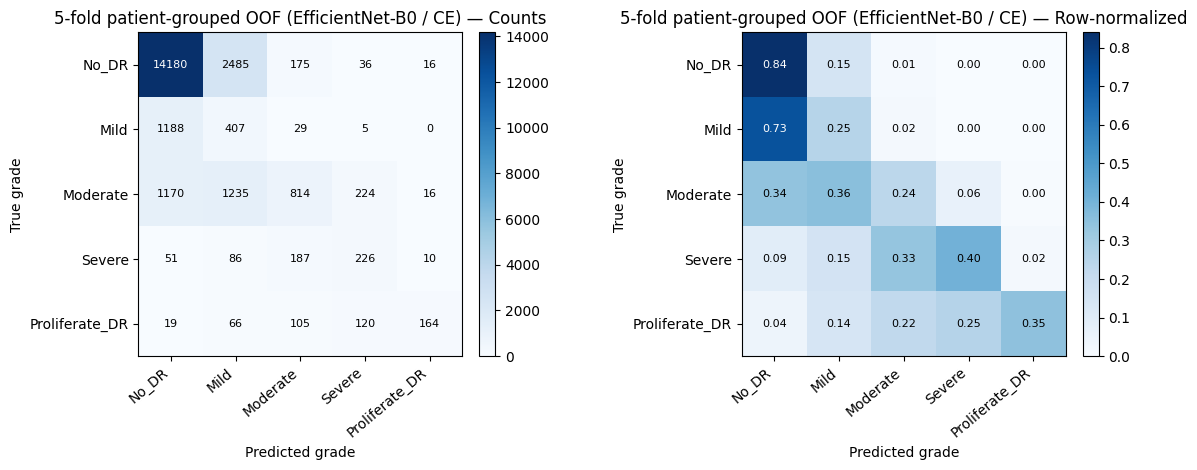

5-fold patient-grouped OOF (EfficientNet-B0 / CE) | {'n': 23014, 'accuracy': 0.6861475623533502, 'macro_f1': 0.43881312410747586, 'quadratic_weighted_kappa': 0.6245263801164938}


,No_DR,Mild,Moderate,Severe,Proliferate_DR
No_DR,14180,2485,175,36,16
Mild,1188,407,29,5,0
Moderate,1170,1235,814,224,16
Severe,51,86,187,226,10
Proliferate_DR,19,66,105,120,164


,precision,recall,f1-score,support
No_DR,0.8538,0.8395,0.8466,16892.0000
Mild,0.0951,0.2498,0.1378,1629.0000
Moderate,0.6214,0.2353,0.3414,3459.0000
Severe,0.3699,0.4036,0.3860,560.0000
Proliferate_DR,0.7961,0.3460,0.4824,474.0000
accuracy,0.6861,0.6861,0.6861,0.6861
macro avg,0.5473,0.4148,0.4388,23014.0000
weighted avg,0.7522,0.6861,0.7018,23014.0000


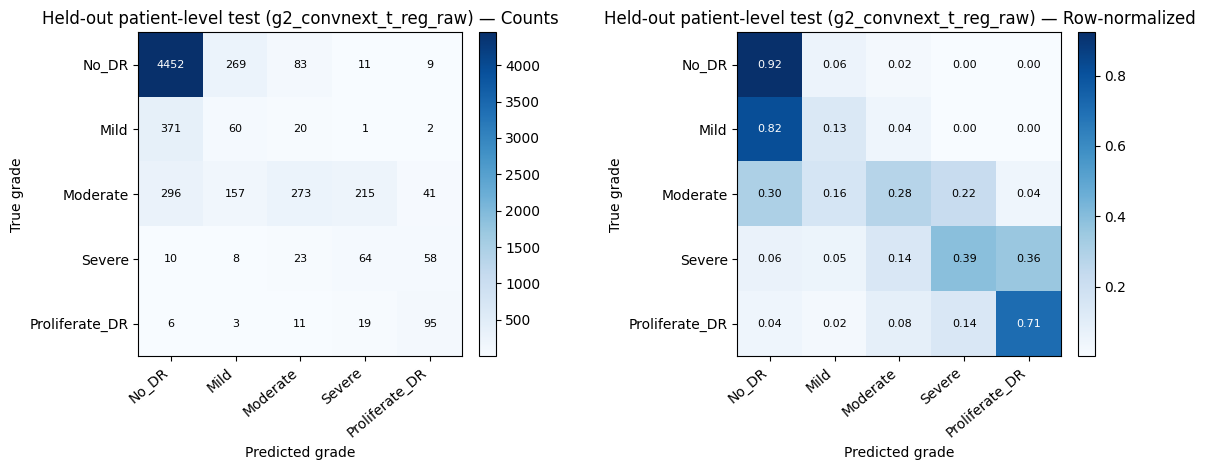

Held-out patient-level test (g2_convnext_t_reg_raw) | {'n': 6557, 'accuracy': 0.7540033551929236, 'macro_f1': 0.44871501961550386, 'quadratic_weighted_kappa': 0.7406602257815311}


,No_DR,Mild,Moderate,Severe,Proliferate_DR
No_DR,4452,269,83,11,9
Mild,371,60,20,1,2
Moderate,296,157,273,215,41
Severe,10,8,23,64,58
Proliferate_DR,6,3,11,19,95


,precision,recall,f1-score,support
No_DR,0.8670,0.9229,0.8941,4824.000
Mild,0.1207,0.1322,0.1262,454.000
Moderate,0.6659,0.2780,0.3922,982.000
Severe,0.2065,0.3926,0.2706,163.000
Proliferate_DR,0.4634,0.7090,0.5605,134.000
accuracy,0.7540,0.7540,0.7540,0.754
macro avg,0.4647,0.4869,0.4487,6557.000
weighted avg,0.7605,0.7540,0.7434,6557.000


Selected model: {'bb': 'convnext_t', 'head': 'reg', 'pp': 'raw', 'tag': 'g2_convnext_t_reg_raw'}
Held-out test metrics:


,QWK,AUROC_ref,Sens_90spec,Sens_95spec,ECE,NLL,Brier,AURC,QWK_80cov
0,0.7407,0.9035,0.7701,0.7037,0.1779,0.8668,0.4632,0.0169,0.6022


Final evaluation files: /kaggle/working/results/final_evaluation


In [28]:
from sklearn.metrics import classification_report, accuracy_score, f1_score

FINAL_EVAL_DIR = RES / "final_evaluation"
FINAL_EVAL_DIR.mkdir(parents=True, exist_ok=True)

def save_confusion_outputs(y_true, y_pred, prefix, title):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(K))
    cm_df = pd.DataFrame(cm, index=CLASSES, columns=CLASSES)
    cm_df.to_csv(FINAL_EVAL_DIR / f"{prefix}_confusion_matrix_counts.csv")
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = cm / np.maximum(row_sums, 1)
    pd.DataFrame(cm_norm, index=CLASSES, columns=CLASSES).to_csv(FINAL_EVAL_DIR / f"{prefix}_confusion_matrix_normalized.csv")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    for ax, mat, label, fmt in [(axes[0], cm, "Counts", "d"), (axes[1], cm_norm, "Row-normalized", ".2f")]:
        im = ax.imshow(mat, cmap="Blues")
        ax.set_title(f"{title} — {label}")
        ax.set_xlabel("Predicted grade"); ax.set_ylabel("True grade")
        ax.set_xticks(range(K), CLASSES, rotation=40, ha="right")
        ax.set_yticks(range(K), CLASSES)
        threshold = float(mat.max()) * 0.55 if mat.size else 0
        for i in range(K):
            for j in range(K):
                ax.text(j, i, format(mat[i, j], fmt), ha="center", va="center", color="white" if mat[i, j] > threshold else "black", fontsize=8)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout(); fig.savefig(FINAL_EVAL_DIR / f"{prefix}_confusion_matrix.png", dpi=180, bbox_inches="tight"); plt.show()
    report = classification_report(y_true, y_pred, labels=np.arange(K), target_names=CLASSES, output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(FINAL_EVAL_DIR / f"{prefix}_classification_report.csv")
    summary = dict(n=int(len(y_true)), accuracy=float(accuracy_score(y_true, y_pred)), macro_f1=float(f1_score(y_true, y_pred, labels=np.arange(K), average="macro", zero_division=0)), quadratic_weighted_kappa=float(qwk(y_true, y_pred)))
    print(title, "|", summary); display(cm_df); display(pd.DataFrame(report).T.round(4))
    return summary

FINAL_EVAL_SUMMARY = {}
if RUN.get("noise", False) and "oof" in globals() and "tr_idx" in globals():
    y_oof = y[tr_idx]
    pred_oof = np.clip(np.rint(np.asarray(oof) @ np.arange(K)), 0, K - 1).astype(int)
    FINAL_EVAL_SUMMARY["five_fold_oof"] = save_confusion_outputs(y_oof, pred_oof, "five_fold_oof", "5-fold patient-grouped OOF (EfficientNet-B0 / CE)")
else:
    print("OOF confusion matrix skipped: run Phase 5 (RUN['noise']=True) to generate predictions from all five folds.")

if "BEST" in globals() and BEST and BEST.get("tag") and (OUT / f"{BEST['tag']}.npz").exists():
    final_run = load_run(BEST["tag"]); final_test = get_eval(final_run, "test")
    FINAL_EVAL_SUMMARY["held_out_test"] = save_confusion_outputs(final_test["y"], final_test["pred"], "held_out_test", f"Held-out patient-level test ({BEST['tag']})")
    final_metrics = metric_row(final_test["P"], final_test["pred"], final_test["y"])
    pd.DataFrame([final_metrics]).to_csv(FINAL_EVAL_DIR / "held_out_test_metrics.csv", index=False)
    print("Selected model:", BEST); print("Held-out test metrics:"); display(pd.DataFrame([final_metrics]).round(4))
else:
    print("Held-out test confusion matrix skipped: run Phase 2 (RUN['grid']=True) to select BEST.")
(FINAL_EVAL_DIR / "summary.json").write_text(json.dumps(FINAL_EVAL_SUMMARY, indent=2))
print("Final evaluation files:", FINAL_EVAL_DIR)

## 17. Export the selected model for testing and download
Run after the final evaluation cell. The export contains the best validation-selected checkpoint, architecture/preprocessing metadata, an inference script, and a README. It exports **weights from the selected notebook run**; it does not train a new model in this cell.

In [ ]:
import zipfile

EXPORT_DIR = WORK / "final_model_export"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

if "BEST" not in globals() or not BEST or not BEST.get("tag"):
    print("No selected model found. Run Phase 2 with RUN['grid']=True before exporting.")
else:
    export_tag = BEST["tag"]
    export_run = load_run(export_tag)
    export_model = load_model(export_tag).to("cpu").eval()
    export_test = get_eval(export_run, "test")
    export_metrics = metric_row(export_test["P"], export_test["pred"], export_test["y"])
    export_config = {
        "model_tag": export_tag,
        "backbone_key": str(export_run["bb"]),
        "timm_name": BB[str(export_run["bb"])]["timm"],
        "model_kwargs": BB[str(export_run["bb"])]["kw"],
        "head": str(export_run["head"]),
        "head_drop": float(CFG["HEAD_DROP"]),
        "preproc": str(export_run["preproc"]),
        "source_img_size": int(SRC_IMG), "img_size": int(IMG), "num_classes": int(K),
        "class_names": list(CLASSES), "sigma": float(export_run["sigma"]),
        "cuts": np.asarray(export_run["cuts"]).astype(float).tolist(),
        "normalization_mean": [0.485, 0.456, 0.406], "normalization_std": [0.229, 0.224, 0.225],
        "timm_version": str(timm.__version__), "torch_version": str(torch.__version__),
        "selected_by": "validation QWK in Phase 2; test set is not used for selection",
        "test_metrics_descriptive_only": {k: float(v) for k, v in export_metrics.items()},
    }
    torch.save({"config": export_config, "state_dict": {k: v.detach().cpu() for k, v in export_model.state_dict().items()}}, EXPORT_DIR / "final_model.pt")
    (EXPORT_DIR / "model_config.json").write_text(json.dumps(export_config, indent=2))
    inference_py = '#!/usr/bin/env python3\n"""Inference helper for final_model.pt. Use only as decision support, not as a diagnosis."""\nimport argparse, json\nimport cv2\nimport numpy as np\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\nimport timm\n\nHEAD_OUT = {"ce": 5, "reg": 1, "corn": 4, "evid": 5}\n\nclass Net(nn.Module):\n    def __init__(self, enc, head, drop):\n        super().__init__()\n        self.enc, self.drop = enc, nn.Dropout(drop)\n        self.fc = nn.Linear(enc.num_features, HEAD_OUT[head])\n    def forward(self, x):\n        return self.fc(self.drop(self.enc(x)))\n\ndef _clahe(img):\n    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)\n    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])\n    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)\n\ndef load_model(bundle_path, device=None):\n    device = device or ("cuda" if torch.cuda.is_available() else "cpu")\n    bundle = torch.load(bundle_path, map_location="cpu", weights_only=False)\n    cfg = bundle["config"]\n    enc = timm.create_model(cfg["timm_name"], pretrained=False, num_classes=0, **cfg["model_kwargs"])\n    model = Net(enc, cfg["head"], cfg["head_drop"])\n    model.load_state_dict(bundle["state_dict"])\n    return model.to(device).eval(), cfg, device\n\ndef predict_image(image_path, bundle_path="final_model.pt", device=None):\n    model, cfg, device = load_model(bundle_path, device)\n    bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)\n    if bgr is None:\n        raise ValueError(f"Could not read image: {image_path}")\n    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)\n    s = int(cfg["source_img_size"])\n    if rgb.shape[:2] != (s, s):\n        rgb = cv2.resize(rgb, (s, s), interpolation=cv2.INTER_AREA)\n    if cfg["preproc"] == "clahe":\n        rgb = _clahe(rgb)\n    x = torch.from_numpy(np.ascontiguousarray(rgb)).permute(2, 0, 1).unsqueeze(0).float() / 255.0\n    x = F.interpolate(x, size=(int(cfg["img_size"]), int(cfg["img_size"])), mode="bilinear", align_corners=False, antialias=True)\n    if cfg["preproc"] == "ben":\n        scale = int(cfg["img_size"]) / s\n        kernel = max(3, int(round(25 * scale)))\n        if kernel % 2 == 0: kernel += 1\n        arr = x[0].permute(1, 2, 0).numpy()\n        blur = cv2.GaussianBlur(arr, (kernel, kernel), 3.7 * scale)\n        x = torch.from_numpy(np.clip(4 * (arr - blur) + 0.5, 0, 1)).permute(2, 0, 1).unsqueeze(0).float()\n    mean = torch.tensor(cfg["normalization_mean"]).view(1, 3, 1, 1)\n    std = torch.tensor(cfg["normalization_std"]).view(1, 3, 1, 1)\n    x = ((x - mean) / std).to(device)\n    with torch.no_grad():\n        logits = model(x).float().cpu().numpy()[0]\n    head = cfg["head"]\n    if head == "ce":\n        z = logits - logits.max(); probs = np.exp(z) / np.exp(z).sum()\n    elif head == "evid":\n        alpha = np.logaddexp(0, logits) + 1; probs = alpha / alpha.sum()\n    elif head == "reg":\n        grades = np.arange(5); probs0 = -((logits[0] - grades) ** 2) / (2 * float(cfg["sigma"]) ** 2)\n        probs0 -= probs0.max(); probs = np.exp(probs0) / np.exp(probs0).sum()\n    else:\n        sig = 1 / (1 + np.exp(-logits)); surv = np.cumprod(sig)\n        probs = np.zeros(5); probs[0] = 1 - surv[0]; probs[1:4] = surv[:-1] - surv[1:]; probs[4] = surv[-1]\n        probs = np.clip(probs, 1e-9, None); probs /= probs.sum()\n    if head == "reg":\n        pred = int(np.digitize([logits[0]], np.asarray(cfg["cuts"]))[0])\n    else:\n        pred = int(np.clip(np.rint(probs @ np.arange(5)), 0, 4))\n    return {"predicted_grade": pred, "predicted_class": cfg["class_names"][pred],\n            "probabilities": {name: float(p) for name, p in zip(cfg["class_names"], probs)},\n            "referable_probability_grade_ge_2": float(probs[2:].sum()),\n            "note": "Research prototype only; not for clinical diagnosis or treatment decisions."}\n\ndef main():\n    p = argparse.ArgumentParser()\n    p.add_argument("image", help="Path to a retinal fundus image")\n    p.add_argument("--model", default="final_model.pt", help="Path to final_model.pt")\n    p.add_argument("--device", default=None, help="Optional torch device, e.g. cpu or cuda")\n    args = p.parse_args()\n    print(json.dumps(predict_image(args.image, args.model, args.device), indent=2))\n\nif __name__ == "__main__":\n    main()\n'
    (EXPORT_DIR / "inference.py").write_text(inference_py)
    readme = f"""# Diabetic Retinopathy Grading — exported model

Files:
- `final_model.pt`: PyTorch model bundle (weights + architecture/preprocessing metadata)
- `model_config.json`: readable model configuration and descriptive test metrics
- `inference.py`: single-image inference helper

## Install
Use a Python environment compatible with the exported PyTorch/timm versions, then install `torch`, `timm`, `numpy`, and `opencv-python`.

## Run
```bash
python inference.py path/to/fundus_image.jpg --model final_model.pt
```

The model was trained from the released {SRC_IMG}x{SRC_IMG} source images and resized to {IMG}x{IMG} at inference to match training. Upsampling does not add lost retinal detail. Results are a research prototype, not a clinical diagnosis.

Selected checkpoint: `{export_tag}`
"""
    (EXPORT_DIR / "README.txt").write_text(readme)
    zip_path = WORK / "final_model_package.zip"
    if zip_path.exists(): zip_path.unlink()
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
        for name in ["final_model.pt", "model_config.json", "inference.py", "README.txt"]:
            zf.write(EXPORT_DIR / name, arcname=name)
    print("Exported model bundle:", EXPORT_DIR / "final_model.pt")
    print("Inference script:", EXPORT_DIR / "inference.py")
    print("Downloadable package:", zip_path)
    print("In Kaggle, download `final_model_package.zip` from the Output panel, or download `final_model.pt` for weights only.")
    del export_model
    gc.collect(); torch.cuda.empty_cache()
